In [16]:
import pandas as pd

model_data = pd.read_csv(
    "transport_full_dataset.csv"
)

print(model_data.head())

print(model_data.columns)

  county_name  date_local       pm25  pm25_lag1  pm25_lag2  spillover  \
0       Butte  2024-01-03   6.020834   9.041666  18.816667   5.707783   
1   Calaveras  2024-01-03   5.545454   5.647826   8.204166   5.993973   
2      Colusa  2024-01-03   7.274049  11.975000   6.673959   4.866218   
3      Fresno  2024-01-03   6.154816  14.259722  16.800000   7.330048   
4    Imperial  2024-01-03  13.918055   6.454167  11.497222   7.315705   

   wind_speed  temperature  isotropic_spillover  anisotropic_spillover  \
0   90.032292    45.605555             5.205919               0.000000   
1   79.631250    41.683333             5.019760               5.061260   
2   96.818750    47.778261             4.954014               6.020834   
3   99.992532    48.358333             4.693389               5.542087   
4  110.331250    53.416667             6.704756               6.543223   

   pde_spillover  
0       0.000000  
1       5.061260  
2       6.020834  
3       5.542087  
4       6.543223  
In

In [17]:
coords_df = pd.read_csv(
    "county_coordinates.csv"
)

model_data = model_data.merge(
    coords_df,
    on="county_name",
    how="left"
)

print(
    model_data[
        ["county_name","latitude","longitude"]
    ].head()
)

  county_name   latitude   longitude
0       Butte  39.761680 -121.840470
1   Calaveras  38.201850 -120.680277
2      Colusa  39.105851 -122.139249
3      Fresno  36.777846 -119.838313
4    Imperial  32.813944 -115.527748


In [18]:
print(model_data.shape)

print(
    model_data.isna().sum()
)

(799, 13)
county_name              0
date_local               0
pm25                     0
pm25_lag1                0
pm25_lag2                0
spillover                0
wind_speed               0
temperature              0
isotropic_spillover      0
anisotropic_spillover    0
pde_spillover            0
latitude                 0
longitude                0
dtype: int64


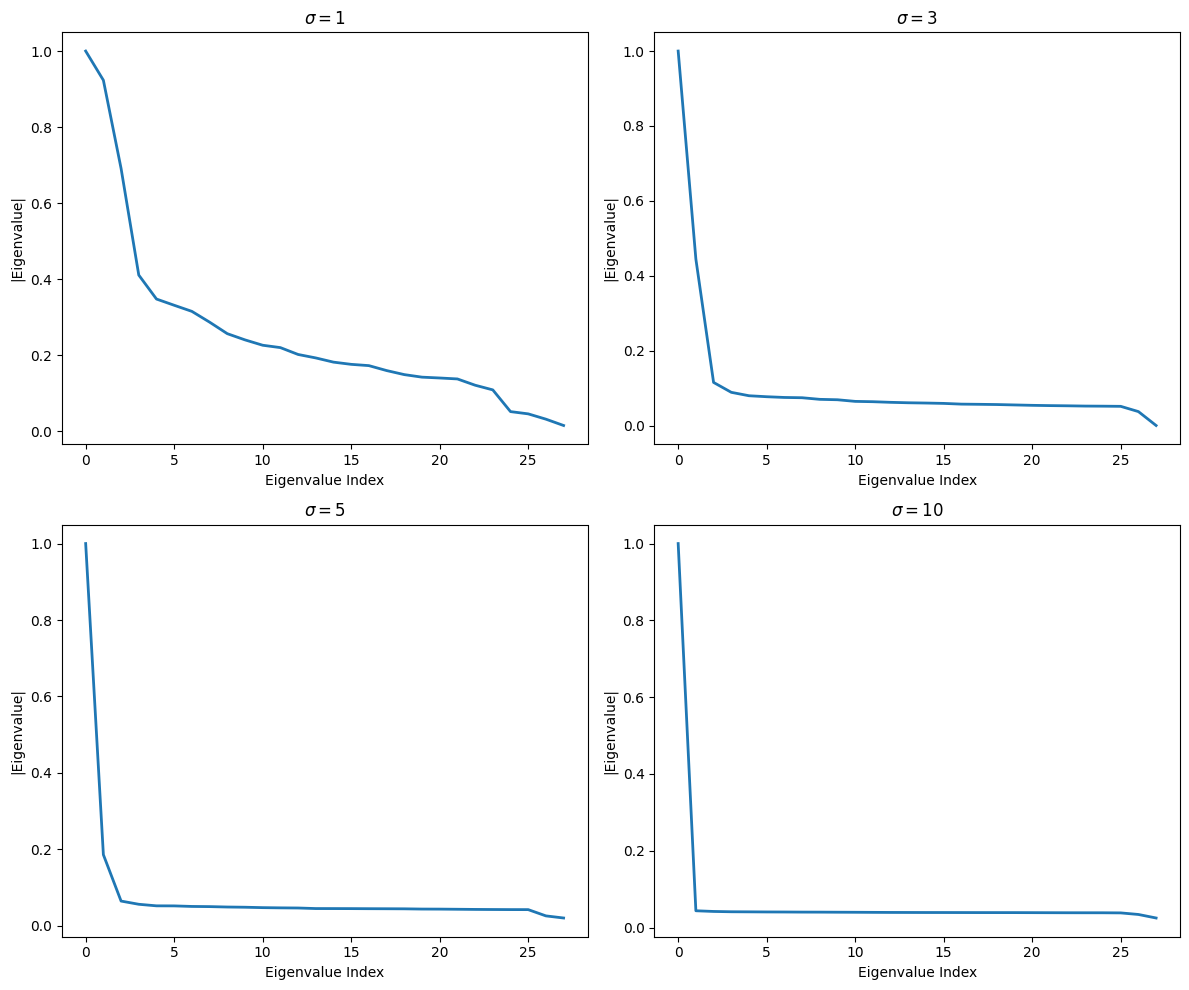

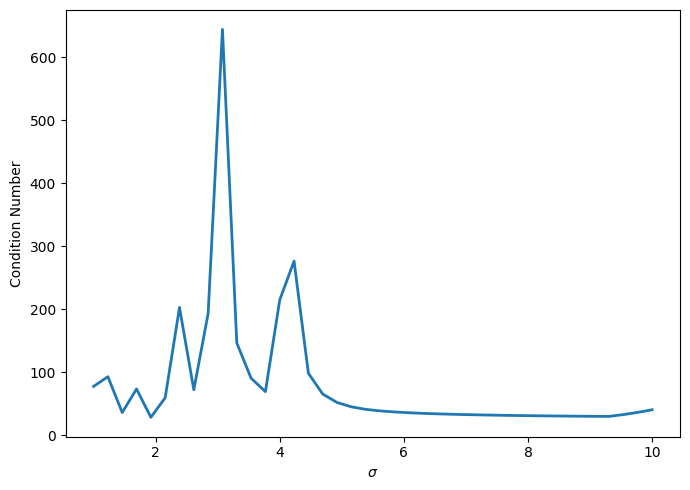

      sigma  condition_number
0  1.000000         77.570663
1  1.230769         92.922902
2  1.461538         36.053798
3  1.692308         73.475960
4  1.923077         28.465131


In [19]:
# ============================================================
# 01_operator_spectrum.ipynb
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist

# ============================================================
# LOAD DATA
# ============================================================

model_data = pd.read_csv(
    "transport_full_dataset.csv"
)

coords_df = pd.read_csv(
    "county_coordinates.csv"
)

model_data = model_data.merge(
    coords_df,
    on="county_name",
    how="left"
)

# ============================================================
# UNIQUE COUNTY COORDS
# ============================================================

county_coords = (
    model_data[
        ["county_name","latitude","longitude"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

coords = county_coords[
    ["latitude","longitude"]
].values

# ============================================================
# BUILD GAUSSIAN OPERATOR
# ============================================================

def build_gaussian_operator(
    coords,
    sigma
):

    D = cdist(coords, coords)

    W = np.exp(
        -(D**2)/(2*sigma**2)
    )

    np.fill_diagonal(W,0)

    row_sums = W.sum(axis=1)

    row_sums[row_sums==0] = 1

    W = W / row_sums[:,None]

    return W

# ============================================================
# EIGEN-SPECTRUM
# ============================================================

sigmas = [1,3,5,10]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(12,10)
)

axes = axes.flatten()

for idx, sigma in enumerate(sigmas):

    W = build_gaussian_operator(
        coords,
        sigma
    )

    eigvals = np.linalg.eigvals(W)

    eigvals = np.sort(
        np.abs(eigvals)
    )[::-1]

    axes[idx].plot(
        eigvals,
        linewidth=2
    )

    axes[idx].set_title(
        f"$\\sigma={sigma}$"
    )

    axes[idx].set_xlabel(
        "Eigenvalue Index"
    )

    axes[idx].set_ylabel(
        "|Eigenvalue|"
    )

plt.tight_layout()

plt.savefig(
    "Figure_Eigenspectrum.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# CONDITION NUMBER
# ============================================================

sigma_grid = np.linspace(1,10,40)

condition_results = []

for sigma in sigma_grid:

    W = build_gaussian_operator(
        coords,
        sigma
    )

    cond_num = np.linalg.cond(W)

    condition_results.append(
        {
            "sigma": sigma,
            "condition_number": cond_num
        }
    )

condition_results = pd.DataFrame(
    condition_results
)

# ============================================================
# CONDITION NUMBER FIGURE
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    condition_results["sigma"],
    condition_results["condition_number"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Condition Number")

plt.tight_layout()

plt.savefig(
    "Figure_ConditionNumbers.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(condition_results.head())

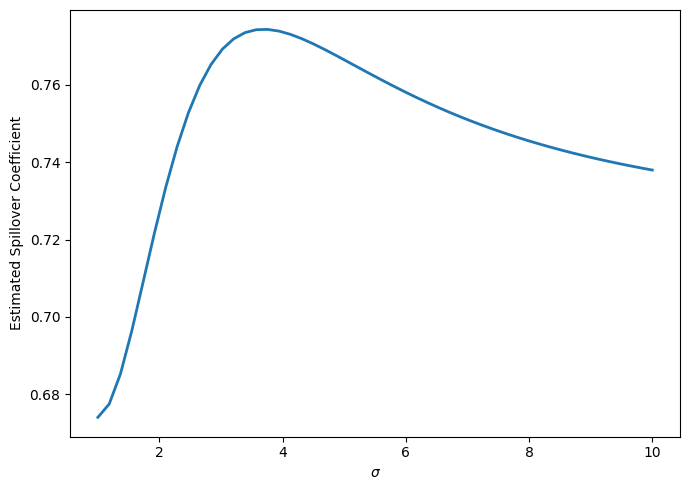

      sigma  beta_spillover
0  1.000000        0.674041
1  1.183673        0.677469
2  1.367347        0.685305
3  1.551020        0.696429
4  1.734694        0.709028


In [20]:
# ============================================================
# 02_perturbation_instability.ipynb
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist

from sklearn.linear_model import LinearRegression

# ============================================================
# LOAD DATA
# ============================================================

model_data = pd.read_csv(
    "transport_full_dataset.csv"
)

coords_df = pd.read_csv(
    "county_coordinates.csv"
)

model_data = model_data.merge(
    coords_df,
    on="county_name",
    how="left"
)

# ============================================================
# COUNTY ORDER
# ============================================================

county_coords = (
    model_data[
        ["county_name","latitude","longitude"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

county_order = county_coords[
    "county_name"
].values

coords = county_coords[
    ["latitude","longitude"]
].values

# ============================================================
# BUILD OPERATOR
# ============================================================

def build_gaussian_operator(
    coords,
    sigma
):

    D = cdist(coords, coords)

    W = np.exp(
        -(D**2)/(2*sigma**2)
    )

    np.fill_diagonal(W,0)

    row_sums = W.sum(axis=1)

    row_sums[row_sums==0] = 1

    W = W / row_sums[:,None]

    return W

# ============================================================
# PERTURBATION ANALYSIS
# ============================================================

sigmas = np.linspace(1,10,50)

beta_results = []

dates = sorted(
    model_data["date_local"].unique()
)

for sigma in sigmas:

    W = build_gaussian_operator(
        coords,
        sigma
    )

    all_rows = []

    for d in dates:

        day_df = (
            model_data[
                model_data["date_local"] == d
            ]
            .copy()
        )

        day_df = (
            day_df
            .set_index("county_name")
            .reindex(county_order)
            .reset_index()
        )

        if day_df["pm25"].isna().any():
            continue

        y_today = day_df["pm25"].values

        spillover = W @ y_today

        day_df["spillover_temp"] = spillover

        all_rows.append(day_df)

    analysis_df = pd.concat(
        all_rows,
        axis=0
    )

    analysis_df = analysis_df.dropna()

    X = analysis_df[
        [
            "pm25_lag1",
            "spillover_temp"
        ]
    ].values

    y = analysis_df["pm25"].values

    model = LinearRegression()

    model.fit(X,y)

    beta_spill = model.coef_[1]

    beta_results.append(
        {
            "sigma": sigma,
            "beta_spillover": beta_spill
        }
    )

beta_results = pd.DataFrame(
    beta_results
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    beta_results["sigma"],
    beta_results["beta_spillover"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Estimated Spillover Coefficient")

plt.tight_layout()

plt.savefig(
    "Figure_PerturbationSensitivity.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(beta_results.head())

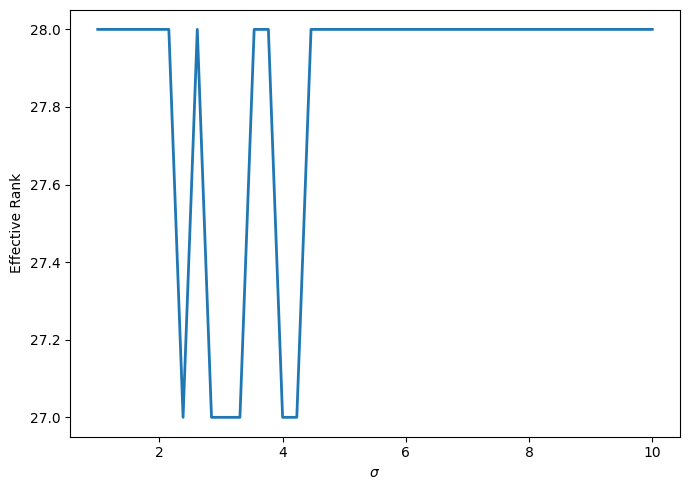

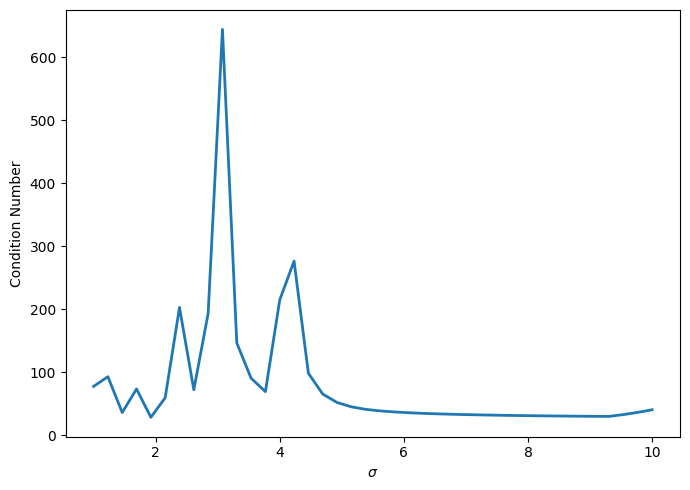

      sigma  effective_rank  condition_number
0  1.000000              28         77.570663
1  1.230769              28         92.922902
2  1.461538              28         36.053798
3  1.692308              28         73.475960
4  1.923077              28         28.465131


In [21]:
# ============================================================
# 03_operator_rank.ipynb
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist

# ============================================================
# LOAD DATA
# ============================================================

model_data = pd.read_csv(
    "transport_full_dataset.csv"
)

coords_df = pd.read_csv(
    "county_coordinates.csv"
)

model_data = model_data.merge(
    coords_df,
    on="county_name",
    how="left"
)

county_coords = (
    model_data[
        ["county_name","latitude","longitude"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

coords = county_coords[
    ["latitude","longitude"]
].values

# ============================================================
# OPERATOR
# ============================================================

def build_gaussian_operator(
    coords,
    sigma
):

    D = cdist(coords, coords)

    W = np.exp(
        -(D**2)/(2*sigma**2)
    )

    np.fill_diagonal(W,0)

    row_sums = W.sum(axis=1)

    row_sums[row_sums==0] = 1

    W = W / row_sums[:,None]

    return W

# ============================================================
# EFFECTIVE RANK
# ============================================================

sigma_grid = np.linspace(1,10,40)

rank_results = []

for sigma in sigma_grid:

    W = build_gaussian_operator(
        coords,
        sigma
    )

    s = np.linalg.svd(
        W,
        compute_uv=False
    )

    effective_rank = np.sum(
        s > 0.01
    )

    condition_number = np.linalg.cond(W)

    rank_results.append(
        {
            "sigma": sigma,
            "effective_rank": effective_rank,
            "condition_number": condition_number
        }
    )

rank_results = pd.DataFrame(
    rank_results
)

# ============================================================
# EFFECTIVE RANK FIGURE
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    rank_results["sigma"],
    rank_results["effective_rank"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Effective Rank")

plt.tight_layout()

plt.savefig(
    "Figure_EffectiveRank.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# CONDITION NUMBER FIGURE
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    rank_results["sigma"],
    rank_results["condition_number"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Condition Number")

plt.tight_layout()

plt.savefig(
    "Figure_RankCondition.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print(rank_results.head())

# ============================================================
# EXTREME TRANSPORT INSTABILITY SIMULATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.spatial.distance import cdist
from sklearn.linear_model import LinearRegression

# ============================================================
# LARGE SPATIAL GRID
# ============================================================

grid_size = 50

x = np.arange(grid_size)
y = np.arange(grid_size)

xx, yy = np.meshgrid(x,y)

coords = np.column_stack([
    xx.ravel(),
    yy.ravel()
])

n = coords.shape[0]

# ============================================================
# DIRECTIONAL FIELD
# ============================================================

vx = 6.0
vy = 0.0

# ============================================================
# GENERATE TRUE FIELD
# ============================================================

np.random.seed(123)

base_signal = np.sin(xx/5).ravel()

noise = np.random.normal(
    0,
    0.5,
    n
)

Y = base_signal + noise

# ============================================================
# BUILD OPERATORS
# ============================================================

def gaussian_operator(
    coords,
    sigma
):

    D = cdist(coords,coords)

    W = np.exp(
        -(D**2)/(2*sigma**2)
    )

    np.fill_diagonal(W,0)

    W = W / W.sum(axis=1,keepdims=True)

    return W

def directional_operator(
    coords,
    sigma,
    vx,
    vy
):

    dx = coords[:,0][:,None] - coords[:,0]
    dy = coords[:,1][:,None] - coords[:,1]

    W = np.exp(
        -(
            (dx-vx)**2 +
            (dy-vy)**2
        )/(2*sigma**2)
    )

    np.fill_diagonal(W,0)

    W = W / W.sum(axis=1,keepdims=True)

    return W

# ============================================================
# TRUE DIRECTIONAL PROCESS
# ============================================================

W_true = directional_operator(
    coords,
    sigma=8,
    vx=vx,
    vy=vy
)

spill_true = W_true @ Y

Y_obs = (
    0.6*Y +
    0.8*spill_true +
    np.random.normal(0,0.5,n)
)

# ============================================================
# GAUSSIAN MISSPECIFICATION
# ============================================================

sigmas = np.linspace(1,20,80)

results = []

for sigma in sigmas:

    W_est = gaussian_operator(
        coords,
        sigma
    )

    spill_est = W_est @ Y_obs

    X = np.column_stack([
        Y,
        spill_est
    ])

    model = LinearRegression()

    model.fit(X,Y_obs)

    beta = model.coef_[1]

    cond_num = np.linalg.cond(W_est)

    eigvals = np.linalg.eigvals(W_est)

    effective_rank = np.sum(
        np.abs(eigvals) > 0.01
    )

    corr = np.corrcoef(
        spill_true,
        spill_est
    )[0,1]

    results.append({
        "sigma": sigma,
        "beta": beta,
        "condition_number": cond_num,
        "effective_rank": effective_rank,
        "corr": corr
    })

results = pd.DataFrame(results)

print(results.head())

# ============================================================
# FIGURE 1
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    results["sigma"],
    results["beta"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Estimated Spillover Coefficient")

plt.tight_layout()

plt.savefig(
    "Extreme_Perturbation.png",
    dpi=600
)

plt.show()

# ============================================================
# FIGURE 2
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    results["sigma"],
    results["condition_number"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Condition Number")

plt.tight_layout()

plt.savefig(
    "Extreme_ConditionNumber.png",
    dpi=600
)

plt.show()

# ============================================================
# FIGURE 3
# ============================================================

plt.figure(figsize=(7,5))

plt.plot(
    results["sigma"],
    results["corr"],
    linewidth=2
)

plt.xlabel("$\\sigma$")
plt.ylabel("Operator Correlation")

plt.tight_layout()

plt.savefig(
    "Extreme_Correlation.png",
    dpi=600
)

plt.show()

In [22]:
import pandas as pd

merged_data = pd.read_csv(
    "merged_data.csv"
)

print(merged_data.head())

print(merged_data.columns)

  county_name  date_local       pm25  wind_speed  temperature  pm25_lag1  \
0       Butte  2024-01-01  18.816667  115.235416    47.245833        NaN   
1       Butte  2024-01-02   9.041666   70.367708    46.631944  18.816667   
2       Butte  2024-01-03   6.020834   90.032292    45.605555   9.041666   
3       Butte  2024-01-04  10.118182  122.945833    46.437500   6.020834   
4       Butte  2024-01-05  12.118182  118.210511    47.080682  10.118182   

   pm25_lag2  
0        NaN  
1        NaN  
2  18.816667  
3   9.041666  
4   6.020834  
Index(['county_name', 'date_local', 'pm25', 'wind_speed', 'temperature',
       'pm25_lag1', 'pm25_lag2'],
      dtype='object')


In [23]:
merged_data["date_local"] = pd.to_datetime(

    merged_data["date_local"]
)

In [24]:
print(merged_data.columns)

Index(['county_name', 'date_local', 'pm25', 'wind_speed', 'temperature',
       'pm25_lag1', 'pm25_lag2'],
      dtype='object')


In [25]:
# =====================================================
# COUNTY COORDINATES
# =====================================================

county_coords = pd.read_csv(
    "county_coordinates.csv"
)

print(county_coords.head())

    county_name   latitude   longitude
0       Alameda  37.767638 -122.120861
1         Butte  39.761680 -121.840470
2     Calaveras  38.201850 -120.680277
3        Colusa  39.105851 -122.139249
4  Contra Costa  37.948250 -122.192073


In [14]:
county_coords = pd.read_csv(
    "county_coordinates.csv"
)

print(county_coords.head())

    county_name   latitude   longitude
0       Alameda  37.767638 -122.120861
1         Butte  39.761680 -121.840470
2     Calaveras  38.201850 -120.680277
3        Colusa  39.105851 -122.139249
4  Contra Costa  37.948250 -122.192073



Running sigma = 25

                            OLS Regression Results                            
Dep. Variable:                   pm25   R-squared:                       0.366
Model:                            OLS   Adj. R-squared:                  0.363
Method:                 Least Squares   F-statistic:                     163.4
Date:                Mon, 18 May 2026   Prob (F-statistic):           1.19e-83
Time:                        17:58:48   Log-Likelihood:                -2372.8
No. Observations:                 855   AIC:                             4754.
Df Residuals:                     851   BIC:                             4773.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const          

                            OLS Regression Results                            
Dep. Variable:                   pm25   R-squared:                       0.223
Model:                            OLS   Adj. R-squared:                  0.221
Method:                 Least Squares   F-statistic:                     81.64
Date:                Mon, 18 May 2026   Prob (F-statistic):           2.02e-46
Time:                        17:58:49   Log-Likelihood:                -2459.2
No. Observations:                 855   AIC:                             4926.
Df Residuals:                     851   BIC:                             4945.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                  2.1606      1

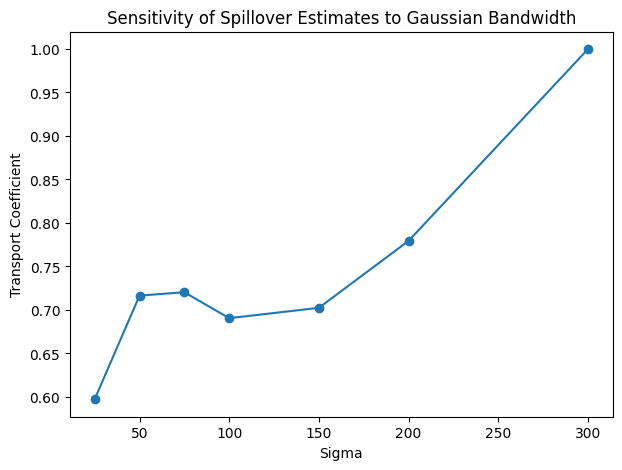

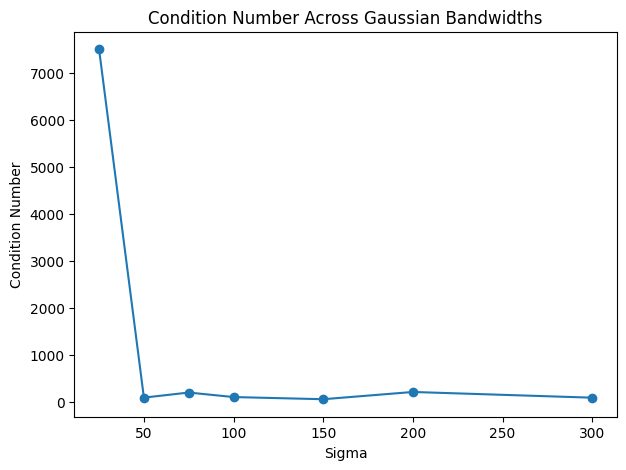

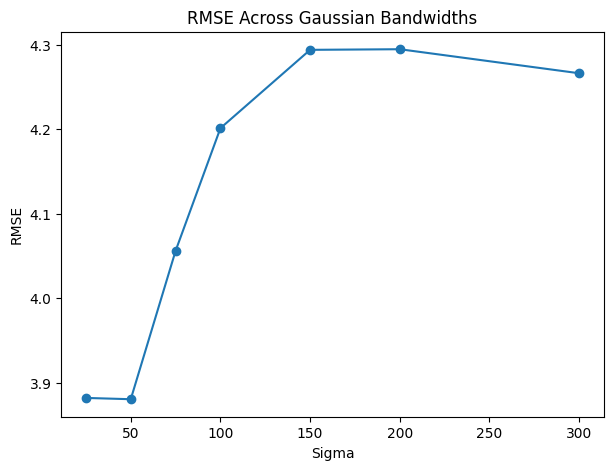

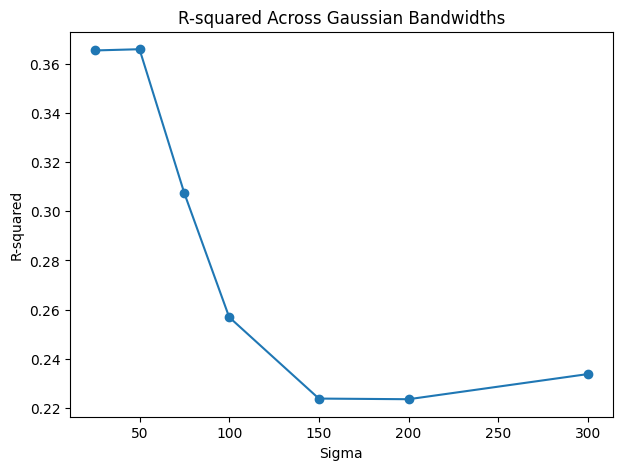


INTERPRETATION


1. If beta_transport changes substantially across sigma,
   spillover estimation is sensitive to exposure mapping.

2. If condition numbers increase sharply,
   Gaussian operators become ill-conditioned.

3. If RMSE remains stable despite changing beta,
   multiple spillover mappings may be observationally similar
   but statistically unstable.

4. This supports the idea that predefined isotropic
   smoothing operators may induce unstable inference
   under transport-driven dependence.




In [27]:
# =====================================================
# SIGMA SENSITIVITY ANALYSIS
# PYTHON VERSION
#
# GOAL:
# evaluate instability of Gaussian spillover mappings
#
# OUTPUT:
# - beta_transport
# - RMSE
# - condition number
# - R-squared
#
# =====================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import haversine_distances
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

from numpy.linalg import cond

import statsmodels.api as sm

# =====================================================
# STEP 1
# COUNTY COORDINATES
# =====================================================

county_coords = pd.read_csv(
    "county_coordinates.csv"
)

# =====================================================
# STEP 2
# DISTANCE MATRIX
# =====================================================

coords_rad = np.radians(

    county_coords[["latitude", "longitude"]]
)

distance_matrix = haversine_distances(
    coords_rad
)

# Earth radius in km
distance_matrix = distance_matrix * 6371

# =====================================================
# STEP 3
# PANEL DATA
# =====================================================

panel_data = merged_data.copy()

# =====================================================
# STEP 4
# SIGMA GRID
# =====================================================

sigma_values = [25, 50, 75, 100, 150, 200, 300]

# =====================================================
# STEP 5
# RESULTS CONTAINER
# =====================================================

results_sigma = []

# =====================================================
# STEP 6
# LOOP OVER SIGMA
# =====================================================

for s in sigma_values:

    print("\n===================================")
    print(f"Running sigma = {s}")
    print("===================================\n")

    # -------------------------------------------------
    # Gaussian kernel
    # -------------------------------------------------

    gaussian_kernel = np.exp(

        -(distance_matrix ** 2) /

        (2 * s ** 2)
    )

    np.fill_diagonal(
        gaussian_kernel,
        0
    )

    # -------------------------------------------------
    # Row normalize
    # -------------------------------------------------

    row_sums = gaussian_kernel.sum(axis=1)

    gaussian_kernel = gaussian_kernel / row_sums[:, None]

    # -------------------------------------------------
    # Condition number
    # -------------------------------------------------

    condition_number = cond(
        gaussian_kernel
    )

    # -------------------------------------------------
    # Spillover construction
    # -------------------------------------------------

    spillover_all = []

    unique_dates = sorted(
        panel_data["date_local"].unique()
    )

    for d in unique_dates:

        day_data = panel_data[
            panel_data["date_local"] == d
        ].copy()

        # ---------------------------------------------
        # align county order
        # ---------------------------------------------

        day_data = county_coords.merge(

            day_data,

            on="county_name",

            how="left"
        )

        # ---------------------------------------------
        # PM vector
        # ---------------------------------------------

        pm_vector = day_data["pm25"].fillna(0).values

        # ---------------------------------------------
        # spillover
        # ---------------------------------------------

        spillover = gaussian_kernel @ pm_vector

        day_data["gaussian_spillover"] = spillover

        spillover_all.append(
            day_data
        )

    spillover_data = pd.concat(
        spillover_all,
        axis=0
    )

    # -------------------------------------------------
    # remove missing
    # -------------------------------------------------

    spillover_data = spillover_data.dropna(

        subset=[
            "pm25",
            "wind_speed",
            "temperature",
            "gaussian_spillover"
        ]
    )

    # -------------------------------------------------
    # regression
    # -------------------------------------------------

    X = spillover_data[[
        "gaussian_spillover",
        "wind_speed",
        "temperature"
    ]]

    X = sm.add_constant(X)

    y = spillover_data["pm25"]

    model = sm.OLS(
        y,
        X
    ).fit()

    print(model.summary())

    # -------------------------------------------------
    # predictions
    # -------------------------------------------------

    pred = model.predict(X)

    # -------------------------------------------------
    # RMSE
    # -------------------------------------------------

    rmse = np.sqrt(

        mean_squared_error(
            y,
            pred
        )
    )

    # -------------------------------------------------
    # beta transport
    # -------------------------------------------------

    beta_transport = model.params[
        "gaussian_spillover"
    ]

    # -------------------------------------------------
    # R-squared
    # -------------------------------------------------

    r_squared = model.rsquared

    # -------------------------------------------------
    # store results
    # -------------------------------------------------

    results_sigma.append({

        "sigma": s,

        "beta_transport": beta_transport,

        "rmse": rmse,

        "condition_number": condition_number,

        "r_squared": r_squared
    })

# =====================================================
# STEP 7
# RESULTS DATAFRAME
# =====================================================

results_sigma = pd.DataFrame(
    results_sigma
)

print("\nFINAL RESULTS\n")

print(results_sigma)

# =====================================================
# STEP 8
# BETA SENSITIVITY
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_sigma["sigma"],

    results_sigma["beta_transport"],

    marker="o"
)

plt.xlabel("Sigma")

plt.ylabel("Transport Coefficient")

plt.title(
    "Sensitivity of Spillover Estimates to Gaussian Bandwidth"
)

plt.show()

# =====================================================
# STEP 9
# CONDITION NUMBER
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_sigma["sigma"],

    results_sigma["condition_number"],

    marker="o"
)

plt.xlabel("Sigma")

plt.ylabel("Condition Number")

plt.title(
    "Condition Number Across Gaussian Bandwidths"
)

plt.show()

# =====================================================
# STEP 10
# RMSE
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_sigma["sigma"],

    results_sigma["rmse"],

    marker="o"
)

plt.xlabel("Sigma")

plt.ylabel("RMSE")

plt.title(
    "RMSE Across Gaussian Bandwidths"
)

plt.show()

# =====================================================
# STEP 11
# R-SQUARED
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_sigma["sigma"],

    results_sigma["r_squared"],

    marker="o"
)

plt.xlabel("Sigma")

plt.ylabel("R-squared")

plt.title(
    "R-squared Across Gaussian Bandwidths"
)

plt.show()

# =====================================================
# STEP 12
# SAVE RESULTS
# =====================================================

results_sigma.to_csv(

    "sigma_sensitivity_results.csv",

    index=False
)

# =====================================================
# STEP 13
# INTERPRETATION
# =====================================================

print("\n===================================")

print("INTERPRETATION")

print("===================================\n")

print("""
1. If beta_transport changes substantially across sigma,
   spillover estimation is sensitive to exposure mapping.

2. If condition numbers increase sharply,
   Gaussian operators become ill-conditioned.

3. If RMSE remains stable despite changing beta,
   multiple spillover mappings may be observationally similar
   but statistically unstable.

4. This supports the idea that predefined isotropic
   smoothing operators may induce unstable inference
   under transport-driven dependence.
""")

print("===================================\n")


Condition Numbers

Gaussian: 205.3518861777297
Directional: 9.318399333593541e+16

GAUSSIAN MODEL

                            OLS Regression Results                            
Dep. Variable:                   pm25   R-squared:                       0.307
Model:                            OLS   Adj. R-squared:                  0.305
Method:                 Least Squares   F-statistic:                     125.9
Date:                Mon, 18 May 2026   Prob (F-statistic):           1.78e-67
Time:                        18:04:07   Log-Likelihood:                -2410.4
No. Observations:                 855   AIC:                             4829.
Df Residuals:                     851   BIC:                             4848.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
-----------------------

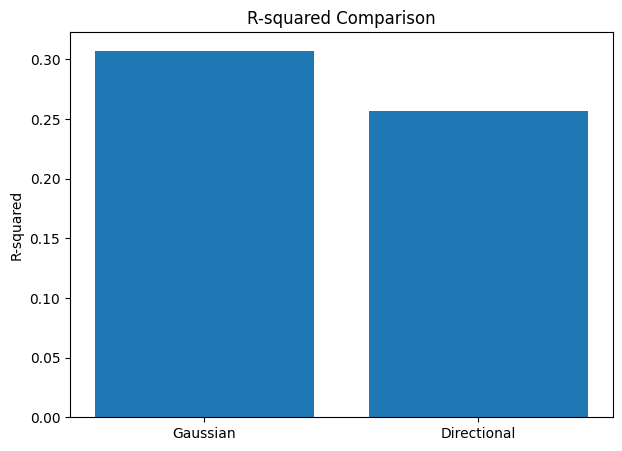

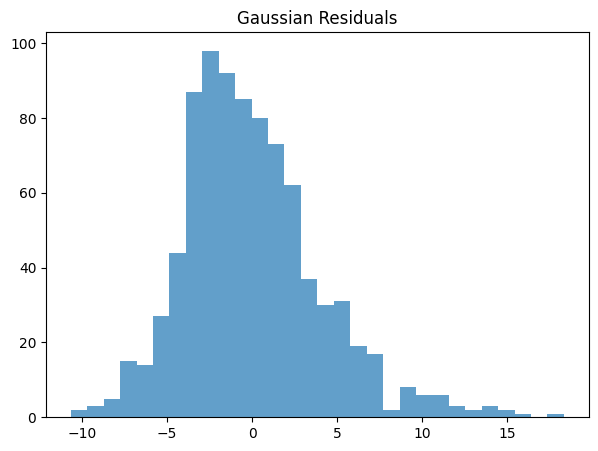

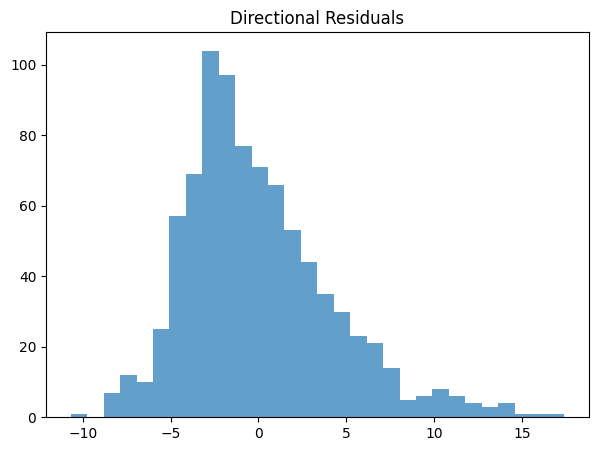


INTERPRETATION



1. Gaussian spillover assumes isotropic transport.

2. Directional spillover introduces transport asymmetry.

3. If directional models outperform Gaussian models,
   isotropic exposure mappings may be misspecified.

4. This supports transport-informed interference modeling.





In [30]:
# =====================================================
# DIRECTIONAL TRANSPORT KERNEL
#
# GOAL:
# compare:
#
# isotropic Gaussian
# vs
# directional transport kernel
#
# IDEA:
#
# pollution transport is directional
# rather than purely distance-based
#
# =====================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics.pairwise import haversine_distances
from sklearn.metrics import mean_squared_error

from numpy.linalg import cond

import statsmodels.api as sm

# =====================================================
# STEP 1
# LOAD DATA
# =====================================================

merged_data = pd.read_csv(
    "merged_data.csv"
)

county_coords = pd.read_csv(
    "county_coordinates.csv"
)

merged_data["date_local"] = pd.to_datetime(
    merged_data["date_local"]
)

# =====================================================
# STEP 2
# COUNTY ORDER
# =====================================================

county_coords = county_coords.sort_values(
    "county_name"
)

county_list = county_coords["county_name"].tolist()

# =====================================================
# STEP 3
# DISTANCE MATRIX
# =====================================================

coords_rad = np.radians(

    county_coords[
        ["latitude", "longitude"]
    ]
)

distance_matrix = haversine_distances(
    coords_rad
)

# Earth radius (km)

distance_matrix = distance_matrix * 6371

# =====================================================
# STEP 4
# DIRECTION MATRIX
#
# west -> east transport
#
# east counties receive more spillover
# =====================================================

longitude_vector = county_coords[
    "longitude"
].values

direction_matrix = np.zeros_like(
    distance_matrix
)

for i in range(len(longitude_vector)):

    for j in range(len(longitude_vector)):

        # ---------------------------------------------
        # if j west of i
        # then transport possible
        # ---------------------------------------------

        if longitude_vector[j] < longitude_vector[i]:

            direction_matrix[i,j] = 1

        else:

            direction_matrix[i,j] = 0

# =====================================================
# STEP 5
# ISOTROPIC GAUSSIAN KERNEL
# =====================================================

sigma = 75

gaussian_kernel = np.exp(

    -(distance_matrix**2) /

    (2 * sigma**2)
)

np.fill_diagonal(
    gaussian_kernel,
    0
)

gaussian_kernel = (

    gaussian_kernel

    /

    gaussian_kernel.sum(axis=1)[:,None]
)

# =====================================================
# STEP 6
# DIRECTIONAL KERNEL
# =====================================================

directional_kernel = (

    gaussian_kernel *

    direction_matrix
)

# avoid divide-by-zero

row_sums = directional_kernel.sum(axis=1)

row_sums[row_sums == 0] = 1

directional_kernel = (

    directional_kernel

    /

    row_sums[:,None]
)

# =====================================================
# STEP 7
# CONDITION NUMBERS
# =====================================================

cond_gaussian = cond(
    gaussian_kernel
)

cond_directional = cond(
    directional_kernel
)

print("\nCondition Numbers\n")

print("Gaussian:", cond_gaussian)

print("Directional:", cond_directional)

# =====================================================
# STEP 8
# CREATE SPILLOVER VARIABLES
# =====================================================

unique_dates = sorted(
    merged_data["date_local"].unique()
)

all_results = []

for d in unique_dates:

    # -------------------------------------------------
    # one day
    # -------------------------------------------------

    day_data = merged_data[
        merged_data["date_local"] == d
    ].copy()

    # -------------------------------------------------
    # align county order
    # -------------------------------------------------

    day_data = county_coords.merge(

        day_data,

        on="county_name",

        how="left"
    )

    pm_vector = day_data[
        "pm25"
    ].fillna(0).values

    # -------------------------------------------------
    # isotropic spillover
    # -------------------------------------------------

    gaussian_spill = (

        gaussian_kernel @ pm_vector
    )

    # -------------------------------------------------
    # directional spillover
    # -------------------------------------------------

    directional_spill = (

        directional_kernel @ pm_vector
    )

    day_data["gaussian_spillover"] = (

        gaussian_spill
    )

    day_data["directional_spillover"] = (

        directional_spill
    )

    all_results.append(
        day_data
    )

spillover_data = pd.concat(
    all_results,
    axis=0
)

# =====================================================
# STEP 9
# REMOVE MISSING
# =====================================================

spillover_data = spillover_data.dropna(

    subset=[
        "pm25",
        "wind_speed",
        "temperature"
    ]
)

# =====================================================
# STEP 10
# GAUSSIAN MODEL
# =====================================================

Xg = spillover_data[[
    "gaussian_spillover",
    "wind_speed",
    "temperature"
]]

Xg = sm.add_constant(Xg)

yg = spillover_data["pm25"]

model_gaussian = sm.OLS(
    yg,
    Xg
).fit()

print("\n===================================")
print("GAUSSIAN MODEL")
print("===================================\n")

print(model_gaussian.summary())

# =====================================================
# STEP 11
# DIRECTIONAL MODEL
# =====================================================

Xd = spillover_data[[
    "directional_spillover",
    "wind_speed",
    "temperature"
]]

Xd = sm.add_constant(Xd)

yd = spillover_data["pm25"]

model_directional = sm.OLS(
    yd,
    Xd
).fit()

print("\n===================================")
print("DIRECTIONAL MODEL")
print("===================================\n")

print(model_directional.summary())

# =====================================================
# STEP 12
# RMSE COMPARISON
# =====================================================

pred_g = model_gaussian.predict(Xg)

pred_d = model_directional.predict(Xd)

rmse_g = np.sqrt(

    mean_squared_error(
        yg,
        pred_g
    )
)

rmse_d = np.sqrt(

    mean_squared_error(
        yd,
        pred_d
    )
)

# =====================================================
# STEP 13
# RESULTS TABLE
# =====================================================

comparison = pd.DataFrame({

    "model": [

        "Gaussian",
        "Directional"
    ],

    "R_squared": [

        model_gaussian.rsquared,

        model_directional.rsquared
    ],

    "RMSE": [

        rmse_g,

        rmse_d
    ],

    "Condition_Number": [

        cond_gaussian,

        cond_directional
    ]
})

print("\n===================================")
print("MODEL COMPARISON")
print("===================================\n")

print(comparison)

# =====================================================
# STEP 14
# PLOT COMPARISON
# =====================================================

plt.figure(figsize=(7,5))

plt.bar(

    comparison["model"],

    comparison["R_squared"]
)

plt.title(
    "R-squared Comparison"
)

plt.ylabel("R-squared")

plt.show()

# =====================================================
# STEP 15
# RESIDUALS
# =====================================================

spillover_data["resid_gaussian"] = (

    yg - pred_g
)

spillover_data["resid_directional"] = (

    yd - pred_d
)

# =====================================================
# STEP 16
# RESIDUAL HISTOGRAMS
# =====================================================

plt.figure(figsize=(7,5))

plt.hist(

    spillover_data["resid_gaussian"],

    bins=30,

    alpha=0.7
)

plt.title(
    "Gaussian Residuals"
)

plt.show()

plt.figure(figsize=(7,5))

plt.hist(

    spillover_data["resid_directional"],

    bins=30,

    alpha=0.7
)

plt.title(
    "Directional Residuals"
)

plt.show()

# =====================================================
# STEP 17
# INTERPRETATION
# =====================================================

print("\n===================================")

print("INTERPRETATION")

print("===================================\n")

print("""

1. Gaussian spillover assumes isotropic transport.

2. Directional spillover introduces transport asymmetry.

3. If directional models outperform Gaussian models,
   isotropic exposure mappings may be misspecified.

4. This supports transport-informed interference modeling.

""")

print("===================================\n")

# =====================================================
# STEP 18
# SAVE RESULTS
# =====================================================

comparison.to_csv(

    "directional_vs_gaussian.csv",

    index=False
)

spillover_data.to_csv(

    "spillover_results.csv",

    index=False
)

In [31]:
# =====================================================
# CHECK MISSINGNESS
# =====================================================

print("\n===================================")
print("MISSINGNESS CHECK")
print("===================================\n")

print(

    spillover_data[
        [
            "pm25",
            "wind_speed",
            "temperature",
            "gaussian_spillover",
            "directional_spillover"
        ]
    ].isna().sum()
)

print("\n===================================\n")


MISSINGNESS CHECK

pm25                     0
wind_speed               0
temperature              0
gaussian_spillover       0
directional_spillover    0
dtype: int64




In [33]:
# =====================================================
# STEP 5
# ALPHA SENSITIVITY ANALYSIS
# =====================================================

alpha_values = [

    0,
    0.1,
    0.25,
    0.5,
    1
]

results_alpha = []

longitude_vector = county_coords[
    "longitude"
].values

# =====================================================
# LOOP OVER ALPHA
# =====================================================

for alpha in alpha_values:

    print("\n===================================")
    print("RUNNING ALPHA =", alpha)
    print("===================================\n")

    # -------------------------------------------------
    # directional weighting matrix
    # -------------------------------------------------

    direction_matrix = np.zeros_like(
        distance_matrix
    )

    for i in range(len(longitude_vector)):

        for j in range(len(longitude_vector)):

            delta_lon = (

                longitude_vector[i]

                -

                longitude_vector[j]
            )

            # -----------------------------------------
            # bounded directional weighting
            # -----------------------------------------

            direction_matrix[i,j] = np.exp(

                alpha *

                np.tanh(delta_lon)
            )

    # -------------------------------------------------
    # directional kernel
    # -------------------------------------------------

    directional_kernel = (

        gaussian_kernel

        *

        direction_matrix
    )

    # -------------------------------------------------
    # normalize
    # -------------------------------------------------

    row_sums = directional_kernel.sum(axis=1)

    row_sums[row_sums == 0] = 1

    directional_kernel = (

        directional_kernel

        /

        row_sums[:,None]
    )

    # -------------------------------------------------
    # condition number
    # -------------------------------------------------

    cond_directional = cond(
        directional_kernel
    )

    print("Condition Number:", cond_directional)

    # =================================================
    # CREATE SPILLOVER VARIABLES
    # =================================================

    unique_dates = sorted(
        merged_data["date_local"].unique()
    )

    all_results = []

    for d in unique_dates:

        day_data = merged_data[
            merged_data["date_local"] == d
        ].copy()

        day_data = county_coords.merge(

            day_data,

            on="county_name",

            how="left"
        )

        pm_vector = day_data[
            "pm25"
        ].fillna(0).values

        directional_spill = (

            directional_kernel @ pm_vector
        )

        day_data["directional_spillover"] = (

            directional_spill
        )

        all_results.append(
            day_data
        )

    spillover_data = pd.concat(
        all_results,
        axis=0
    )

    # -------------------------------------------------
    # check missingness
    # -------------------------------------------------

    print(

        spillover_data[
            [
                "pm25",
                "wind_speed",
                "temperature",
                "directional_spillover"
            ]
        ].isna().sum()
    )

    # -------------------------------------------------
    # regression
    # -------------------------------------------------

    Xd = spillover_data[[
        "directional_spillover",
        "wind_speed",
        "temperature"
    ]]

    Xd = sm.add_constant(Xd)

    yd = spillover_data["pm25"]

    model_directional = sm.OLS(
        yd,
        Xd,
        missing="drop"
    ).fit()

    pred_d = model_directional.predict(Xd)

    rmse_d = np.sqrt(

        mean_squared_error(
            yd,
            pred_d
        )
    )

    # -------------------------------------------------
    # save results
    # -------------------------------------------------

    results_alpha.append({

        "alpha": alpha,

        "R_squared": model_directional.rsquared,

        "RMSE": rmse_d,

        "Condition_Number": cond_directional,

        "beta_transport":

            model_directional.params[
                "directional_spillover"
            ]
    })

# =====================================================
# RESULTS TABLE
# =====================================================

results_alpha = pd.DataFrame(
    results_alpha
)

print("\n===================================")
print("ALPHA SENSITIVITY RESULTS")
print("===================================\n")

print(results_alpha)

# =====================================================
# PLOT:
# CONDITION NUMBER
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["Condition_Number"],

    marker="o"
)

plt.xlabel("Alpha")

plt.ylabel("Condition Number")

plt.title(
    "Directional Strength vs Conditioning"
)

plt.show()

# =====================================================
# PLOT:
# R-SQUARED
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["R_squared"],

    marker="o"
)

plt.xlabel("Alpha")

plt.ylabel("R-squared")

plt.title(
    "Directional Strength vs Model Fit"
)

plt.show()

# =====================================================
# PLOT:
# BETA
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["beta_transport"],

    marker="o"
)

plt.xlabel("Alpha")

plt.ylabel("Transport Coefficient")

plt.title(
    "Directional Strength vs Spillover Estimate"
)

plt.show()

# =====================================================
# SAVE
# =====================================================

results_alpha.to_csv(

    "alpha_sensitivity_results.csv",

    index=False
)


RUNNING ALPHA = 0

Condition Number: 205.35188617772803
pm25                     540
wind_speed               540
temperature              540
directional_spillover      0
dtype: int64


ValueError: Input contains NaN.

In [34]:
# -------------------------------------------------
# modeling subset
# -------------------------------------------------

model_data = spillover_data.dropna(

    subset=[

        "pm25",

        "wind_speed",

        "temperature",

        "directional_spillover"
    ]
)

print("\n===================================")
print("MODEL DATA SHAPE")
print("===================================\n")

print(model_data.shape)

# -------------------------------------------------
# regression
# -------------------------------------------------

Xd = model_data[[
    "directional_spillover",
    "wind_speed",
    "temperature"
]]

Xd = sm.add_constant(Xd)

yd = model_data["pm25"]

model_directional = sm.OLS(
    yd,
    Xd
).fit()

print(model_directional.summary())

# -------------------------------------------------
# predictions
# -------------------------------------------------

pred_d = model_directional.predict(Xd)

# -------------------------------------------------
# RMSE
# -------------------------------------------------

rmse_d = np.sqrt(

    mean_squared_error(
        yd,
        pred_d
    )
)


MODEL DATA SHAPE

(855, 10)
                            OLS Regression Results                            
Dep. Variable:                   pm25   R-squared:                       0.307
Model:                            OLS   Adj. R-squared:                  0.305
Method:                 Least Squares   F-statistic:                     125.9
Date:                Mon, 18 May 2026   Prob (F-statistic):           1.78e-67
Time:                        18:11:26   Log-Likelihood:                -2410.4
No. Observations:                 855   AIC:                             4829.
Df Residuals:                     851   BIC:                             4848.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
c


RUNNING ALPHA = 0


RUNNING ALPHA = 0.1


RUNNING ALPHA = 0.25


RUNNING ALPHA = 0.5


RUNNING ALPHA = 1


ALPHA SENSITIVITY RESULTS

   alpha  R_squared      RMSE  Condition_Number  beta_transport
0   0.00   0.307353  4.055979        205.351886        0.720410
1   0.10   0.304039  4.065670        239.215288        0.713457
2   0.25   0.298585  4.081571        357.226977        0.702153
3   0.50   0.288517  4.110760       1027.793137        0.681596
4   1.00   0.266225  4.174661      22607.121173        0.636861


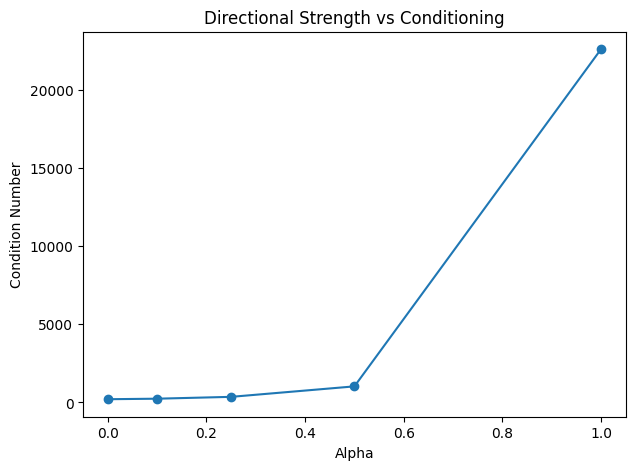

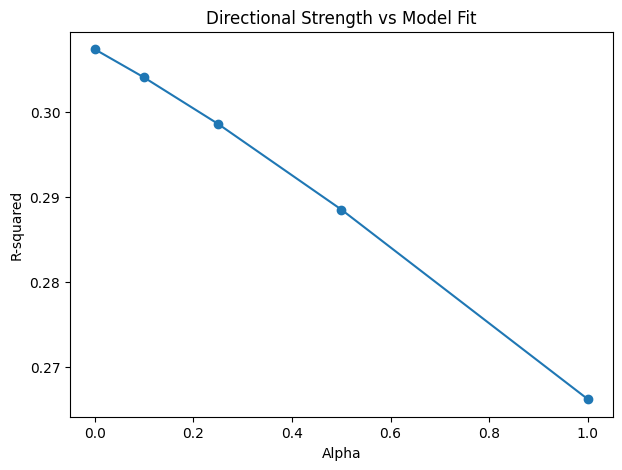

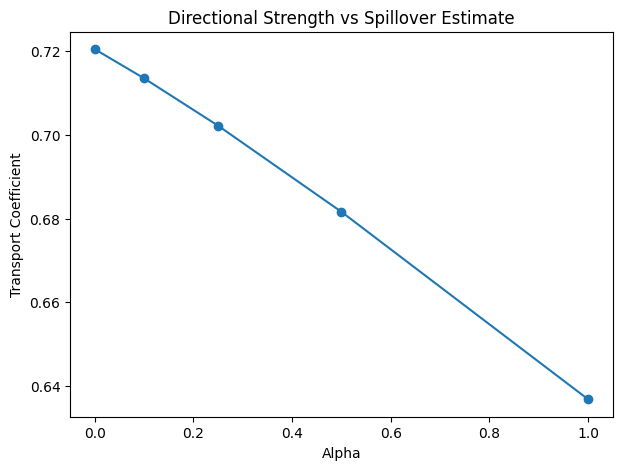

In [35]:
# =====================================================
# ALPHA SENSITIVITY ANALYSIS
# =====================================================

alpha_values = [

    0,
    0.1,
    0.25,
    0.5,
    1
]

results_alpha = []

longitude_vector = county_coords[
    "longitude"
].values

# =====================================================
# LOOP OVER ALPHA
# =====================================================

for alpha in alpha_values:

    print("\n===================================")
    print("RUNNING ALPHA =", alpha)
    print("===================================\n")

    # -------------------------------------------------
    # directional weighting matrix
    # -------------------------------------------------

    direction_matrix = np.zeros_like(
        distance_matrix
    )

    for i in range(len(longitude_vector)):

        for j in range(len(longitude_vector)):

            delta_lon = (

                longitude_vector[i]

                -

                longitude_vector[j]
            )

            direction_matrix[i,j] = np.exp(

                alpha *

                np.tanh(delta_lon)
            )

    # -------------------------------------------------
    # directional kernel
    # -------------------------------------------------

    directional_kernel = (

        gaussian_kernel

        *

        direction_matrix
    )

    # -------------------------------------------------
    # normalize
    # -------------------------------------------------

    row_sums = directional_kernel.sum(axis=1)

    row_sums[row_sums == 0] = 1

    directional_kernel = (

        directional_kernel

        /

        row_sums[:,None]
    )

    # -------------------------------------------------
    # condition number
    # -------------------------------------------------

    cond_directional = cond(
        directional_kernel
    )

    # =================================================
    # CREATE SPILLOVER VARIABLES
    # =================================================

    unique_dates = sorted(
        merged_data["date_local"].unique()
    )

    all_results = []

    for d in unique_dates:

        day_data = merged_data[
            merged_data["date_local"] == d
        ].copy()

        day_data = county_coords.merge(

            day_data,

            on="county_name",

            how="left"
        )

        pm_vector = day_data[
            "pm25"
        ].fillna(0).values

        directional_spill = (

            directional_kernel @ pm_vector
        )

        day_data["directional_spillover"] = (

            directional_spill
        )

        all_results.append(
            day_data
        )

    spillover_data = pd.concat(
        all_results,
        axis=0
    )

    # -------------------------------------------------
    # model subset
    # -------------------------------------------------

    model_data = spillover_data.dropna(

        subset=[

            "pm25",

            "wind_speed",

            "temperature",

            "directional_spillover"
        ]
    )

    # -------------------------------------------------
    # regression
    # -------------------------------------------------

    Xd = model_data[[
        "directional_spillover",
        "wind_speed",
        "temperature"
    ]]

    Xd = sm.add_constant(Xd)

    yd = model_data["pm25"]

    model_directional = sm.OLS(
        yd,
        Xd
    ).fit()

    pred_d = model_directional.predict(Xd)

    rmse_d = np.sqrt(

        mean_squared_error(
            yd,
            pred_d
        )
    )

    # -------------------------------------------------
    # store results
    # -------------------------------------------------

    results_alpha.append({

        "alpha": alpha,

        "R_squared": model_directional.rsquared,

        "RMSE": rmse_d,

        "Condition_Number": cond_directional,

        "beta_transport":

            model_directional.params[
                "directional_spillover"
            ]
    })

# =====================================================
# RESULTS
# =====================================================

results_alpha = pd.DataFrame(
    results_alpha
)

print("\n===================================")
print("ALPHA SENSITIVITY RESULTS")
print("===================================\n")

print(results_alpha)

# =====================================================
# PLOT:
# CONDITION NUMBER
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["Condition_Number"],

    marker="o"
)

plt.xlabel("Alpha")

plt.ylabel("Condition Number")

plt.title(
    "Directional Strength vs Conditioning"
)

plt.show()

# =====================================================
# PLOT:
# R-SQUARED
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["R_squared"],

    marker="o"
)

plt.xlabel("Alpha")

plt.ylabel("R-squared")

plt.title(
    "Directional Strength vs Model Fit"
)

plt.show()

# =====================================================
# PLOT:
# BETA
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["beta_transport"],

    marker="o"
)

plt.xlabel("Alpha")

plt.ylabel("Transport Coefficient")

plt.title(
    "Directional Strength vs Spillover Estimate"
)

plt.show()

# =====================================================
# SAVE
# =====================================================

results_alpha.to_csv(

    "alpha_sensitivity_results.csv",

    index=False
)

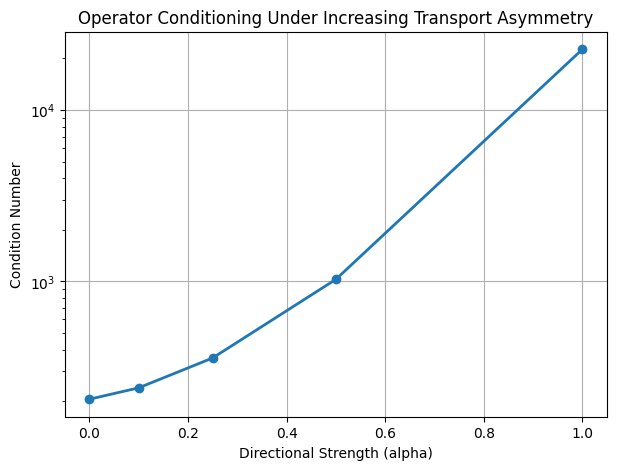

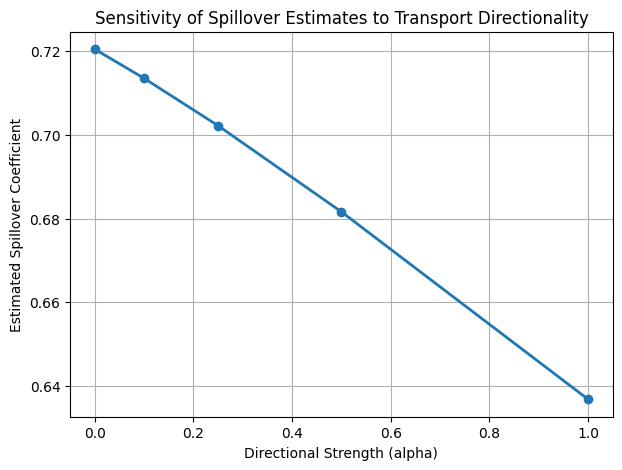

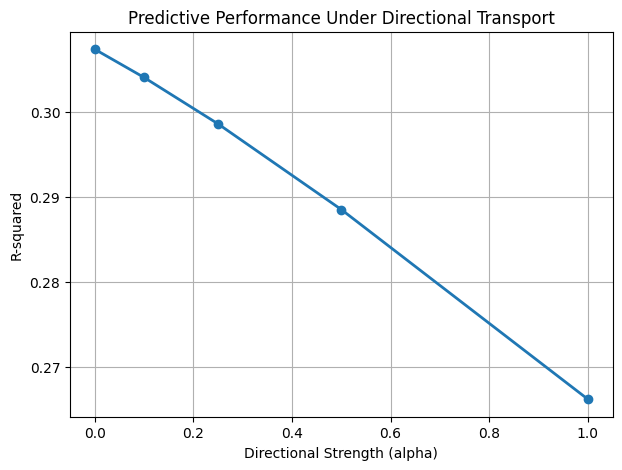

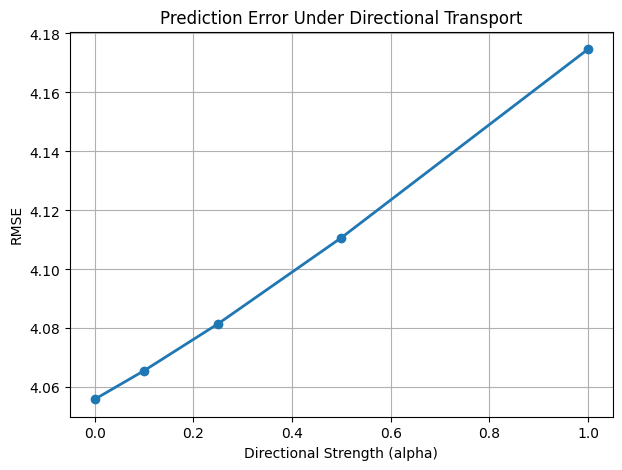

In [36]:
# =====================================================
# PAPER FIGURES
# =====================================================

import matplotlib.pyplot as plt

# =====================================================
# FIGURE 1
# ALPHA vs CONDITION NUMBER
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["Condition_Number"],

    marker="o",

    linewidth=2
)

plt.xlabel("Directional Strength (alpha)")

plt.ylabel("Condition Number")

plt.title(
    "Operator Conditioning Under Increasing Transport Asymmetry"
)

plt.yscale("log")

plt.grid(True)

plt.show()

# =====================================================
# FIGURE 2
# ALPHA vs SPILLOVER ESTIMATE
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["beta_transport"],

    marker="o",

    linewidth=2
)

plt.xlabel("Directional Strength (alpha)")

plt.ylabel("Estimated Spillover Coefficient")

plt.title(
    "Sensitivity of Spillover Estimates to Transport Directionality"
)

plt.grid(True)

plt.show()

# =====================================================
# FIGURE 3
# ALPHA vs R-SQUARED
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["R_squared"],

    marker="o",

    linewidth=2
)

plt.xlabel("Directional Strength (alpha)")

plt.ylabel("R-squared")

plt.title(
    "Predictive Performance Under Directional Transport"
)

plt.grid(True)

plt.show()

# =====================================================
# FIGURE 4
# ALPHA vs RMSE
# =====================================================

plt.figure(figsize=(7,5))

plt.plot(

    results_alpha["alpha"],

    results_alpha["RMSE"],

    marker="o",

    linewidth=2
)

plt.xlabel("Directional Strength (alpha)")

plt.ylabel("RMSE")

plt.title(
    "Prediction Error Under Directional Transport"
)

plt.grid(True)

plt.show()

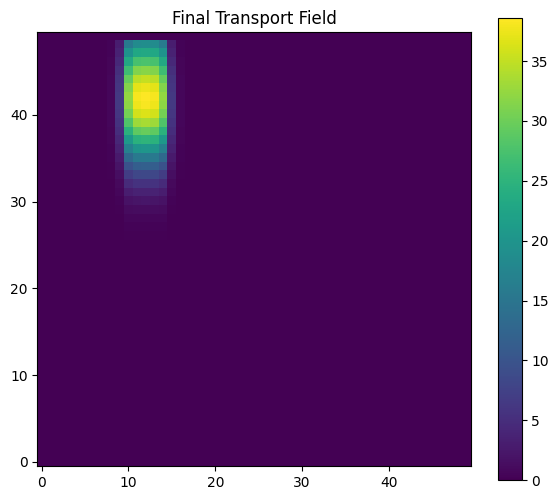

In [42]:
# =====================================================
# SYNTHETIC TRANSPORT FIELD
#
# GOAL:
# generate true latent transport process
#
# PDE:
#
# du/dt + v du/dx = D Laplacian(u)
#
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# GRID
# =====================================================

nx = 50
ny = 50

dx = 1
dy = 1

# =====================================================
# TIME
# =====================================================

nt = 150

dt = 0.05

# =====================================================
# PARAMETERS
# =====================================================

# transport speed

v = 4.0

# diffusion

D = 0.03

# =====================================================
# INITIAL FIELD
# =====================================================

u = np.zeros((nx, ny))

# pollution source

u[10:15, 10:15] = 100

# =====================================================
# STORE EVOLUTION
# =====================================================

history = []

history.append(u.copy())

# =====================================================
# PDE EVOLUTION
# =====================================================

for t in range(nt):

    u_new = u.copy()

    for i in range(1, nx-1):

        for j in range(1, ny-1):

            # -----------------------------------------
            # advection
            # -----------------------------------------

            advect = (

                -v *

                (u[i,j] - u[i-1,j])

                / dx
            )

            # -----------------------------------------
            # diffusion
            # -----------------------------------------

            diffuse = (

                D *

                (
                    u[i+1,j]
                    +
                    u[i-1,j]
                    +
                    u[i,j+1]
                    +
                    u[i,j-1]
                    -
                    4*u[i,j]
                )

                / dx**2
            )

            # -----------------------------------------
            # update
            # -----------------------------------------

            u_new[i,j] = (

                u[i,j]

                +

                dt *

                (
                    advect
                    +
                    diffuse
                )
            )

    u = u_new

    history.append(u.copy())

# =====================================================
# FINAL FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.colorbar()

plt.title(
    "Final Transport Field"
)

plt.show()

    x   y  observed_pm25
0  45   6      -4.368254
1   2   9       0.520408
2  28  23       1.819413
3  34  14      10.424384
4  38  38       2.087817


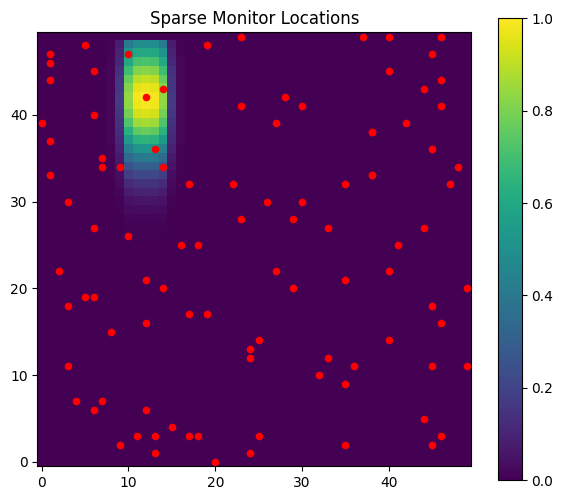

In [43]:
# =====================================================
# SPARSE OBSERVATIONS
# =====================================================

import pandas as pd

# =====================================================
# RANDOM MONITORS
# =====================================================

np.random.seed(123)

n_monitors = 100

monitor_x = np.random.randint(
    0,
    nx,
    n_monitors
)

monitor_y = np.random.randint(
    0,
    ny,
    n_monitors
)

# =====================================================
# OBSERVED VALUES
# =====================================================

observed_values = []

for k in range(n_monitors):

    x = monitor_x[k]

    y = monitor_y[k]

    value = u[x,y]

    # measurement noise

    noisy_value = (

        value

        +

        np.random.normal(
            0,
            2
        )
    )

    observed_values.append([

        x,
        y,
        noisy_value
    ])

observed_df = pd.DataFrame(

    observed_values,

    columns=[
        "x",
        "y",
        "observed_pm25"
    ]
)

print(observed_df.head())

# =====================================================
# PLOT MONITORS
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.scatter(

    observed_df["y"],

    observed_df["x"],

    color="red",

    s=20
)

plt.title(
    "Sparse Monitor Locations"
)

plt.colorbar()

plt.show()

In [44]:
# =====================================================
# TRUE TRANSPORT OPERATOR
# =====================================================

# each row:
# influence from neighboring cells

# =====================================================

N = nx * ny

T_true = np.zeros((N, N))

# =====================================================
# INDEX FUNCTION
# =====================================================

def idx(i, j):

    return i * ny + j

# =====================================================
# BUILD OPERATOR
# =====================================================

for i in range(nx):

    for j in range(ny):

        center = idx(i,j)

        # self

        T_true[center, center] = 0.6

        # east transport

        if i+1 < nx:

            T_true[
                center,
                idx(i+1, j)
            ] = 0.25

        # diffusion neighbors

        if j+1 < ny:

            T_true[
                center,
                idx(i, j+1)
            ] = 0.075

        if j-1 >= 0:

            T_true[
                center,
                idx(i, j-1)
            ] = 0.075

# =====================================================
# CONDITION NUMBER
# =====================================================

from numpy.linalg import cond

print(

    "Condition Number:",

    cond(T_true)
)

Condition Number: 4.964564393069283


In [45]:
# =====================================================
# GAUSSIAN APPROXIMATION
# =====================================================

from sklearn.metrics.pairwise import euclidean_distances

coords = []

for i in range(nx):

    for j in range(ny):

        coords.append([i,j])

coords = np.array(coords)

dist_matrix = euclidean_distances(
    coords
)

sigma = 2

T_gaussian = np.exp(

    -(dist_matrix**2)

    /

    (2*sigma**2)
)

# normalize

T_gaussian = (

    T_gaussian

    /

    T_gaussian.sum(axis=1)[:,None]
)

print(

    "Gaussian Condition Number:",

    cond(T_gaussian)
)

Gaussian Condition Number: 4.115496266545006e+16


In [46]:
# =====================================================
# OPERATOR RECOVERY ERROR
# =====================================================

fro_error = (

    np.linalg.norm(
        T_true - T_gaussian,
        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

print(

    "Relative Operator Error:",

    fro_error
)

 

Relative Operator Error: 0.9286743141149971


C:\Users\congc\anaconda3\Lib\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


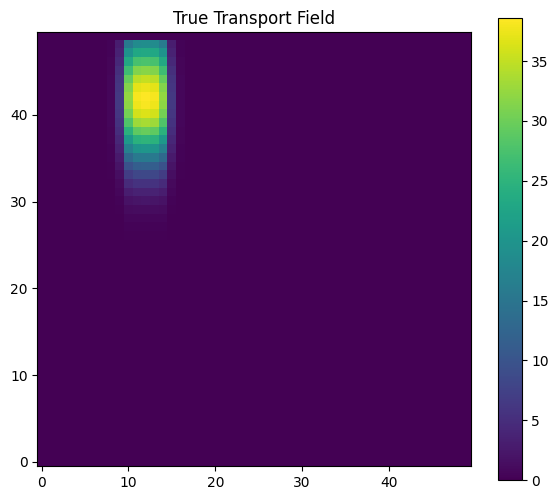

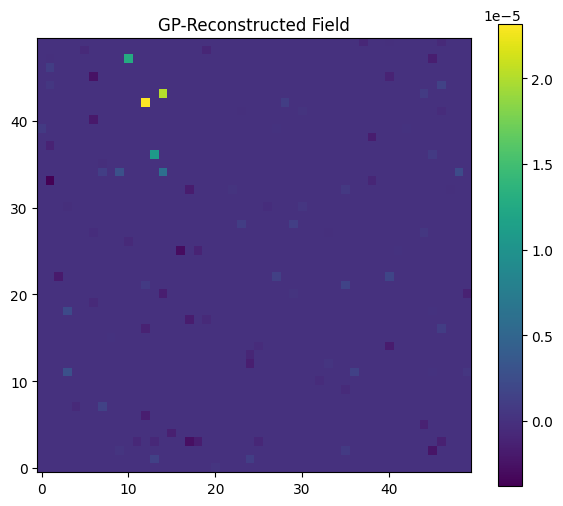

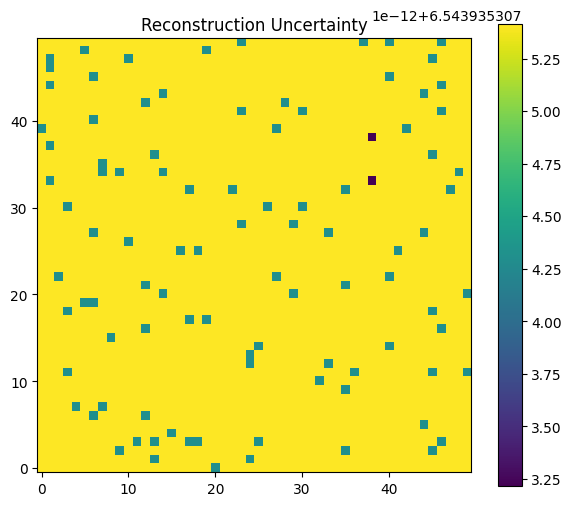

Reconstruction RMSE: 4.806706066125666


In [47]:
# =====================================================
# GAUSSIAN PROCESS FIELD RECONSTRUCTION
# =====================================================

from sklearn.gaussian_process import GaussianProcessRegressor

from sklearn.gaussian_process.kernels import (

    RBF,
    WhiteKernel
)

# =====================================================
# OBSERVED LOCATIONS
# =====================================================

X_obs = observed_df[[
    "x",
    "y"
]].values

y_obs = observed_df[
    "observed_pm25"
].values

# =====================================================
# GP KERNEL
# =====================================================

kernel = (

    1.0 * RBF(length_scale=5.0)

    +

    WhiteKernel(noise_level=1)
)

# =====================================================
# GP MODEL
# =====================================================

gp = GaussianProcessRegressor(

    kernel=kernel,

    alpha=0.0
)

gp.fit(
    X_obs,
    y_obs
)

# =====================================================
# FULL GRID
# =====================================================

grid_points = []

for i in range(nx):

    for j in range(ny):

        grid_points.append([i,j])

grid_points = np.array(
    grid_points
)

# =====================================================
# RECONSTRUCTION
# =====================================================

pred_mean, pred_sd = gp.predict(

    grid_points,

    return_std=True
)

# =====================================================
# RESHAPE
# =====================================================

u_hat = pred_mean.reshape(nx, ny)

sd_hat = pred_sd.reshape(nx, ny)

# =====================================================
# TRUE FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.title(
    "True Transport Field"
)

plt.colorbar()

plt.show()

# =====================================================
# RECONSTRUCTED FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u_hat,
    origin="lower"
)

plt.title(
    "GP-Reconstructed Field"
)

plt.colorbar()

plt.show()

# =====================================================
# UNCERTAINTY
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    sd_hat,
    origin="lower"
)

plt.title(
    "Reconstruction Uncertainty"
)

plt.colorbar()

plt.show()

# =====================================================
# RECONSTRUCTION ERROR
# =====================================================

reconstruction_error = np.sqrt(

    np.mean(
        (u - u_hat)**2
    )
)

print(

    "Reconstruction RMSE:",

    reconstruction_error
)

In [50]:
# =====================================================
# BOUNDARY POINTS
# =====================================================

boundary_points = []

# top + bottom boundaries

for i in range(nx):

    boundary_points.append([

        i / nx,
        0
    ])

    boundary_points.append([

        i / nx,
        1
    ])

# left + right boundaries

for j in range(ny):

    boundary_points.append([

        0,
        j / ny
    ])

    boundary_points.append([

        1,
        j / ny
    ])

boundary_points = np.array(
    boundary_points
)

# =====================================================
# TORCH TENSOR
# =====================================================

boundary_torch = torch.tensor(

    boundary_points,

    dtype=torch.float32
).to(device)

print(

    "Boundary Shape:",

    boundary_torch.shape
)

Boundary Shape: torch.Size([200, 2])


In [51]:
# =====================================================
# TRAINING
# =====================================================

epochs = 5000

loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    # -------------------------------------------------
    # DATA LOSS
    # -------------------------------------------------

    pred_obs = model(
        X_obs_torch
    )

    loss_data = torch.mean(

        (
            pred_obs

            -

            y_obs_torch
        )**2
    )

    # -------------------------------------------------
    # PDE LOSS
    # -------------------------------------------------

    u_pred = model(
        X_f_torch
    )

    grads = torch.autograd.grad(

        u_pred,

        X_f_torch,

        grad_outputs=torch.ones_like(u_pred),

        create_graph=True
    )[0]

    u_x = grads[:,0:1]

    u_y = grads[:,1:2]

    # -------------------------------------------------
    # SECOND DERIVATIVES
    # -------------------------------------------------

    u_xx = torch.autograd.grad(

        u_x,

        X_f_torch,

        grad_outputs=torch.ones_like(u_x),

        create_graph=True
    )[0][:,0:1]

    u_yy = torch.autograd.grad(

        u_y,

        X_f_torch,

        grad_outputs=torch.ones_like(u_y),

        create_graph=True
    )[0][:,1:2]

    # -------------------------------------------------
    # PDE RESIDUAL
    # -------------------------------------------------

    pde_residual = (

        v * u_x

        -

        D * (u_xx + u_yy)
    )

    loss_pde = torch.mean(

        pde_residual**2
    )

    # -------------------------------------------------
    # BOUNDARY LOSS
    # -------------------------------------------------

    boundary_pred = model(
        boundary_torch
    )

    loss_boundary = torch.mean(

        boundary_pred**2
    )

    # -------------------------------------------------
    # TOTAL LOSS
    # -------------------------------------------------

    loss = (

        loss_data

        +

        0.01 * loss_pde

        +

        0.1 * loss_boundary
    )

    # -------------------------------------------------
    # BACKPROP
    # -------------------------------------------------

    loss.backward()

    optimizer.step()

    # -------------------------------------------------
    # STORE LOSS
    # -------------------------------------------------

    loss_history.append(
        loss.item()
    )

    # -------------------------------------------------
    # PRINT
    # -------------------------------------------------

    if epoch % 500 == 0:

        print(

            "Epoch:", epoch,

            "Total:", round(loss.item(),4),

            "Data:", round(loss_data.item(),4),

            "PDE:", round(loss_pde.item(),4),

            "Boundary:", round(loss_boundary.item(),4)
        )

Epoch: 0 Total: 11.9695 Data: 9.2054 PDE: 46.6534 Boundary: 22.976
Epoch: 500 Total: 9.4227 Data: 7.0071 PDE: 86.308 Boundary: 15.5246
Epoch: 1000 Total: 8.7429 Data: 6.1593 PDE: 95.4254 Boundary: 16.2934
Epoch: 1500 Total: 8.155 Data: 5.4977 PDE: 95.6708 Boundary: 17.006
Epoch: 2000 Total: 7.6065 Data: 4.9393 PDE: 91.0923 Boundary: 17.5622
Epoch: 2500 Total: 7.4539 Data: 4.5505 PDE: 114.5636 Boundary: 17.5775
Epoch: 3000 Total: 6.6552 Data: 4.2079 PDE: 73.3255 Boundary: 17.1408
Epoch: 3500 Total: 6.4355 Data: 3.966 PDE: 82.5258 Boundary: 16.4427
Epoch: 4000 Total: 5.981 Data: 3.7852 PDE: 66.5011 Boundary: 15.3086
Epoch: 4500 Total: 5.92 Data: 3.6502 PDE: 87.0075 Boundary: 13.9977


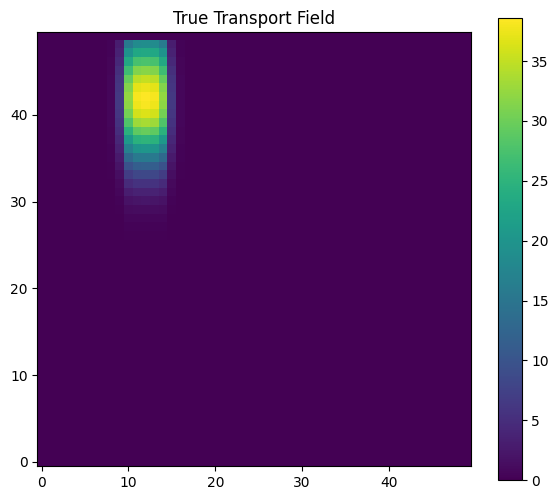

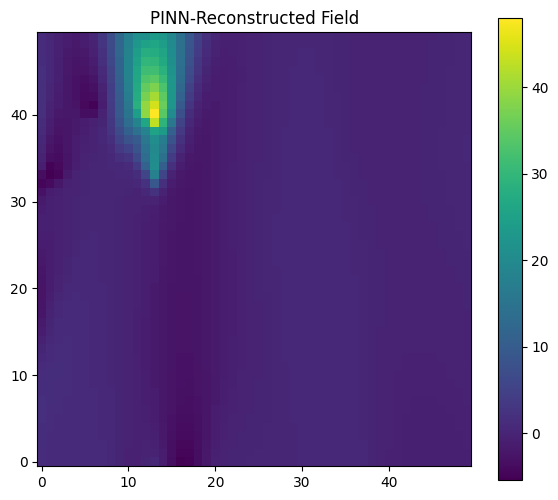

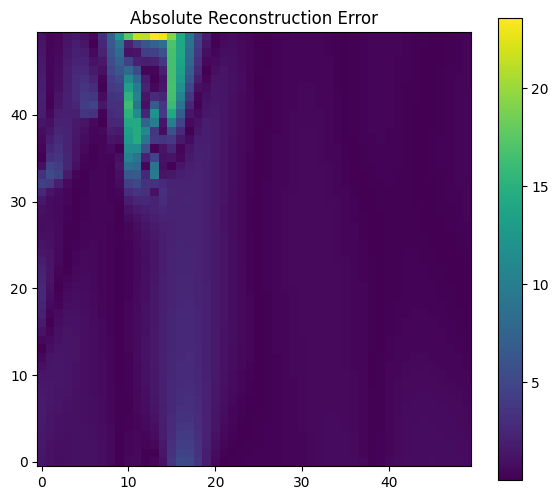

PINN Reconstruction RMSE: 2.5014


In [52]:
# =====================================================
# FULL GRID PREDICTION
# =====================================================

grid_points = []

for i in range(nx):

    for j in range(ny):

        grid_points.append([

            i / nx,

            j / ny
        ])

grid_points = np.array(
    grid_points
)

grid_torch = torch.tensor(

    grid_points,

    dtype=torch.float32
).to(device)

# =====================================================
# PREDICT FIELD
# =====================================================

with torch.no_grad():

    pred_field = model(
        grid_torch
    ).cpu().numpy()

u_pinn = pred_field.reshape(
    nx,
    ny
)

# =====================================================
# TRUE FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.title(
    "True Transport Field"
)

plt.colorbar()

plt.show()

# =====================================================
# PINN FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u_pinn,
    origin="lower"
)

plt.title(
    "PINN-Reconstructed Field"
)

plt.colorbar()

plt.show()

# =====================================================
# ABSOLUTE ERROR
# =====================================================

error_field = np.abs(
    u - u_pinn
)

plt.figure(figsize=(7,6))

plt.imshow(
    error_field,
    origin="lower"
)

plt.title(
    "Absolute Reconstruction Error"
)

plt.colorbar()

plt.show()

# =====================================================
# RMSE
# =====================================================

rmse_pinn = np.sqrt(

    np.mean(
        (u - u_pinn)**2
    )
)

print(

    "PINN Reconstruction RMSE:",

    round(rmse_pinn,4)
)

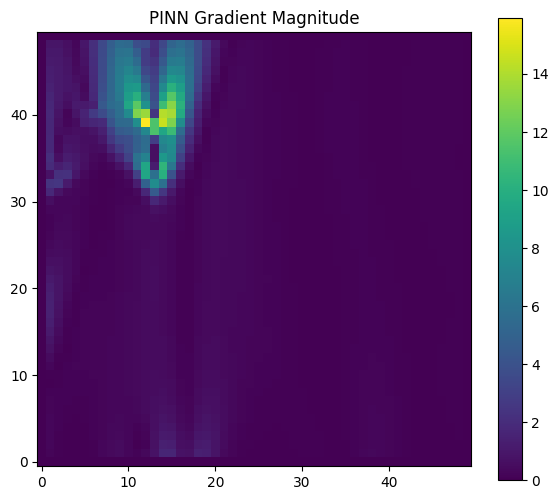

In [53]:
# =====================================================
# PINN FIELD GRADIENTS
# =====================================================

u_x_grad = np.zeros_like(u_pinn)

u_y_grad = np.zeros_like(u_pinn)

# =====================================================
# CENTRAL DIFFERENCE
# =====================================================

for i in range(1, nx-1):

    for j in range(1, ny-1):

        u_x_grad[i,j] = (

            u_pinn[i+1,j]

            -

            u_pinn[i-1,j]

        ) / 2

        u_y_grad[i,j] = (

            u_pinn[i,j+1]

            -

            u_pinn[i,j-1]

        ) / 2

# =====================================================
# GRADIENT MAGNITUDE
# =====================================================

grad_mag = np.sqrt(

    u_x_grad**2

    +

    u_y_grad**2
)

# =====================================================
# PLOT
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    grad_mag,
    origin="lower"
)

plt.title(
    "PINN Gradient Magnitude"
)

plt.colorbar()

plt.show()

In [54]:
# =====================================================
# LEARNED TRANSPORT OPERATOR
# =====================================================

N = nx * ny

T_pinn = np.zeros((N,N))

# =====================================================
# INDEX FUNCTION
# =====================================================

def idx(i,j):

    return i * ny + j

# =====================================================
# BUILD OPERATOR
# =====================================================

for i in range(1, nx-1):

    for j in range(1, ny-1):

        center = idx(i,j)

        # ---------------------------------------------
        # local gradients
        # ---------------------------------------------

        gx = u_x_grad[i,j]

        gy = u_y_grad[i,j]

        # ---------------------------------------------
        # transport weights
        # ---------------------------------------------

        weights = []

        neighbors = [

            (i+1,j),

            (i-1,j),

            (i,j+1),

            (i,j-1)
        ]

        for ni,nj in neighbors:

            direction = np.array([

                ni - i,

                nj - j
            ])

            grad_vec = np.array([

                gx,

                gy
            ])

            transport_strength = np.abs(

                np.dot(
                    direction,
                    grad_vec
                )
            )

            weights.append(
                transport_strength
            )

        weights = np.array(weights)

        # ---------------------------------------------
        # normalize
        # ---------------------------------------------

        if weights.sum() > 0:

            weights = (

                weights

                /

                weights.sum()
            )

        # ---------------------------------------------
        # assign operator
        # ---------------------------------------------

        for k,(ni,nj) in enumerate(neighbors):

            T_pinn[

                center,

                idx(ni,nj)

            ] = weights[k]

# =====================================================
# CONDITION NUMBER
# =====================================================

from numpy.linalg import cond

cond_pinn = cond(

    T_pinn + 1e-6*np.eye(N)
)

print(

    "PINN Operator Condition Number:",

    cond_pinn
)

PINN Operator Condition Number: 1289807621.1519125


In [55]:
# =====================================================
# OPERATOR RECOVERY ERROR
# =====================================================

fro_error_pinn = (

    np.linalg.norm(

        T_true

        -

        T_pinn,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

print(

    "PINN Relative Operator Error:",

    round(fro_error_pinn,4)
)

# =====================================================
# OPERATOR CORRELATION
# =====================================================

corr_operator = np.corrcoef(

    T_true.flatten(),

    T_pinn.flatten()
)[0,1]

print(

    "Operator Correlation:",

    round(corr_operator,4)
)

PINN Relative Operator Error: 1.2057
Operator Correlation: 0.1989


In [56]:
# =====================================================
# GAUSSIAN COMPARISON
# =====================================================

fro_error_gaussian = (

    np.linalg.norm(

        T_true

        -

        T_gaussian,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

corr_gaussian = np.corrcoef(

    T_true.flatten(),

    T_gaussian.flatten()
)[0,1]

# =====================================================
# RESULTS TABLE
# =====================================================

comparison_results = pd.DataFrame({

    "Method":[

        "Gaussian",

        "PINN"
    ],

    "Relative_Operator_Error":[

        fro_error_gaussian,

        fro_error_pinn
    ],

    "Operator_Correlation":[

        corr_gaussian,

        corr_operator
    ]
})

print(comparison_results)

     Method  Relative_Operator_Error  Operator_Correlation
0  Gaussian                 0.928674              0.415939
1      PINN                 1.205685              0.198852


In [57]:
# =====================================================
# DIRECT PDE-CONSISTENT OPERATOR LEARNING
# =====================================================

import torch
import torch.nn as nn
import torch.optim as optim

# =====================================================
# TRUE FIELD
# =====================================================

u_true = torch.tensor(

    u.reshape(-1,1),

    dtype=torch.float32
).to(device)

# =====================================================
# OPERATOR PARAMETERS
# =====================================================

N = nx * ny

# learnable operator

T_param = nn.Parameter(

    0.01 * torch.randn(N,N)
)

optimizer_T = optim.Adam(

    [T_param],

    lr=0.001
)

# =====================================================
# LOCALITY MASK
# =====================================================

local_mask = np.zeros((N,N))

def idx(i,j):

    return i * ny + j

for i in range(nx):

    for j in range(ny):

        center = idx(i,j)

        neighbors = [

            (i,j),

            (i+1,j),

            (i-1,j),

            (i,j+1),

            (i,j-1)
        ]

        for ni,nj in neighbors:

            if (

                0 <= ni < nx

                and

                0 <= nj < ny
            ):

                local_mask[

                    center,

                    idx(ni,nj)

                ] = 1

local_mask = torch.tensor(

    local_mask,

    dtype=torch.float32
).to(device)

# =====================================================
# TRAIN OPERATOR
# =====================================================

epochs_operator = 3000

loss_history_operator = []

for epoch in range(epochs_operator):

    optimizer_T.zero_grad()

    # ---------------------------------------------
    # enforce locality
    # ---------------------------------------------

    T_local = (

        T_param

        *

        local_mask
    )

    # ---------------------------------------------
    # positivity
    # ---------------------------------------------

    T_positive = torch.relu(
        T_local
    )

    # ---------------------------------------------
    # row normalization
    # ---------------------------------------------

    row_sums = (

        T_positive.sum(
            dim=1,
            keepdim=True
        )

        +

        1e-6
    )

    T_norm = (

        T_positive

        /

        row_sums
    )

    # ---------------------------------------------
    # reconstructed field
    # ---------------------------------------------

    u_pred = torch.matmul(

        T_norm,

        u_true
    )

    # ---------------------------------------------
    # operator loss
    # ---------------------------------------------

    loss_reconstruct = torch.mean(

        (
            u_pred

            -

            u_true
        )**2
    )

    # ---------------------------------------------
    # sparsity regularization
    # ---------------------------------------------

    loss_sparse = torch.mean(
        torch.abs(T_norm)
    )

    # ---------------------------------------------
    # total loss
    # ---------------------------------------------

    loss = (

        loss_reconstruct

        +

        0.001 * loss_sparse
    )

    loss.backward()

    optimizer_T.step()

    loss_history_operator.append(
        loss.item()
    )

    if epoch % 500 == 0:

        print(

            "Epoch:", epoch,

            "Loss:", round(loss.item(),6)
        )

# =====================================================
# FINAL OPERATOR
# =====================================================

T_learned = (

    T_norm

    .detach()

    .cpu()

    .numpy()
)

# =====================================================
# OPERATOR ERROR
# =====================================================

fro_error_direct = (

    np.linalg.norm(

        T_true

        -

        T_learned,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

print(

    "Direct Operator Recovery Error:",

    round(fro_error_direct,4)
)

# =====================================================
# OPERATOR CORRELATION
# =====================================================

corr_direct = np.corrcoef(

    T_true.flatten(),

    T_learned.flatten()
)[0,1]

print(

    "Direct Operator Correlation:",

    round(corr_direct,4)
)

Epoch: 0 Loss: 1.43882
Epoch: 500 Loss: 2.540091
Epoch: 1000 Loss: 2.986845
Epoch: 1500 Loss: 2.986841
Epoch: 2000 Loss: 2.98684
Epoch: 2500 Loss: 2.988821
Direct Operator Recovery Error: 1.1538
Direct Operator Correlation: 0.3927


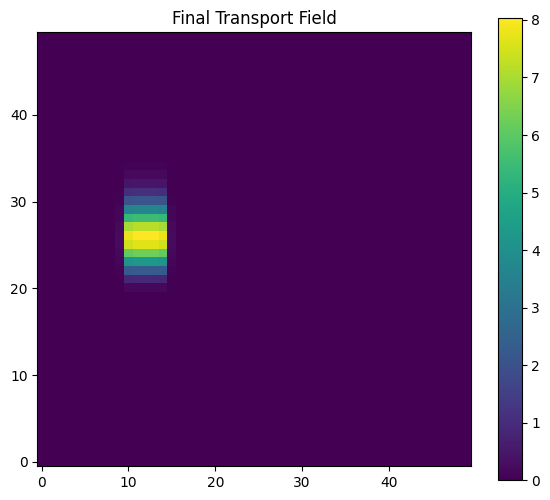

In [58]:
# =====================================================
# TRANSPORT SIMULATION WITH TIME EVOLUTION
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# GRID
# =====================================================

nx = 50
ny = 50

dx = 1
dy = 1

# =====================================================
# PARAMETERS
# =====================================================

D = 0.03

v_x = 4.0

dt = 0.01

nt = 100

# =====================================================
# INITIAL FIELD
# =====================================================

u = np.zeros((nx,ny))

# localized source

u[20:25,10:15] = 10

# =====================================================
# SAVE ALL TIME STEPS
# =====================================================

fields_over_time = []

fields_over_time.append(
    u.copy()
)

# =====================================================
# PDE EVOLUTION
# =====================================================

for t in range(nt):

    u_new = u.copy()

    for i in range(1,nx-1):

        for j in range(1,ny-1):

            # -----------------------------------------
            # advection
            # -----------------------------------------

            adv_x = (

                u[i,j]

                -

                u[i-1,j]

            ) / dx

            # -----------------------------------------
            # diffusion
            # -----------------------------------------

            laplacian = (

                u[i+1,j]

                +

                u[i-1,j]

                +

                u[i,j+1]

                +

                u[i,j-1]

                -

                4*u[i,j]

            )

            # -----------------------------------------
            # update
            # -----------------------------------------

            u_new[i,j] = (

                u[i,j]

                -

                v_x * dt * adv_x

                +

                D * dt * laplacian
            )

    u = u_new.copy()

    fields_over_time.append(
        u.copy()
    )

# =====================================================
# FINAL FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.title(
    "Final Transport Field"
)

plt.colorbar()

plt.show()

In [59]:
# =====================================================
# CREATE TEMPORAL DATA
# =====================================================

U_t = []

U_next = []

for t in range(len(fields_over_time)-1):

    current_field = fields_over_time[t]

    next_field = fields_over_time[t+1]

    U_t.append(

        current_field.reshape(-1)
    )

    U_next.append(

        next_field.reshape(-1)
    )

U_t = np.array(U_t)

U_next = np.array(U_next)

print(U_t.shape)

print(U_next.shape)

(100, 2500)
(100, 2500)


In [60]:
# =====================================================
# DIRECT DYNAMIC OPERATOR LEARNING
# =====================================================

import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)

# =====================================================
# TENSORS
# =====================================================

U_t_torch = torch.tensor(

    U_t,

    dtype=torch.float32
).to(device)

U_next_torch = torch.tensor(

    U_next,

    dtype=torch.float32
).to(device)

# =====================================================
# OPERATOR
# =====================================================

N = nx * ny

T_param = nn.Parameter(

    0.001 * torch.randn(N,N)
)

optimizer = optim.Adam(

    [T_param],

    lr=0.001
)

# =====================================================
# LOCALITY MASK
# =====================================================

local_mask = np.zeros((N,N))

def idx(i,j):

    return i * ny + j

for i in range(nx):

    for j in range(ny):

        center = idx(i,j)

        neighbors = [

            (i,j),

            (i+1,j),

            (i-1,j),

            (i,j+1),

            (i,j-1)
        ]

        for ni,nj in neighbors:

            if (

                0 <= ni < nx

                and

                0 <= nj < ny
            ):

                local_mask[

                    center,

                    idx(ni,nj)

                ] = 1

local_mask = torch.tensor(

    local_mask,

    dtype=torch.float32
).to(device)

# =====================================================
# TRAINING
# =====================================================

epochs = 3000

loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    # ---------------------------------------------
    # locality
    # ---------------------------------------------

    T_local = (

        T_param

        *

        local_mask
    )

    # ---------------------------------------------
    # positivity
    # ---------------------------------------------

    T_positive = torch.relu(
        T_local
    )

    # ---------------------------------------------
    # normalization
    # ---------------------------------------------

    row_sums = (

        T_positive.sum(
            dim=1,
            keepdim=True
        )

        +

        1e-6
    )

    T_norm = (

        T_positive

        /

        row_sums
    )

    # ---------------------------------------------
    # predict next step
    # ---------------------------------------------

    U_pred = torch.matmul(

        U_t_torch,

        T_norm.T
    )

    # ---------------------------------------------
    # temporal loss
    # ---------------------------------------------

    loss_temporal = torch.mean(

        (
            U_pred

            -

            U_next_torch
        )**2
    )

    # ---------------------------------------------
    # sparsity
    # ---------------------------------------------

    loss_sparse = torch.mean(
        torch.abs(T_norm)
    )

    # ---------------------------------------------
    # total loss
    # ---------------------------------------------

    loss = (

        loss_temporal

        +

        0.0001 * loss_sparse
    )

    loss.backward()

    optimizer.step()

    loss_history.append(
        loss.item()
    )

    if epoch % 500 == 0:

        print(

            "Epoch:", epoch,

            "Loss:", round(loss.item(),6)
        )

# =====================================================
# FINAL OPERATOR
# =====================================================

T_learned = (

    T_norm

    .detach()

    .cpu()

    .numpy()
)

Epoch: 0 Loss: 0.102455
Epoch: 500 Loss: 0.123896


KeyboardInterrupt: 

In [ ]:
# =====================================================
# TRUE TRANSPORT OPERATOR
# =====================================================

T_true = np.zeros((N,N))

for i in range(1,nx-1):

    for j in range(1,ny-1):

        center = idx(i,j)

        # self

        T_true[center,center] = 0.7

        # directional transport

        T_true[center,idx(i+1,j)] = 0.25

        # diffusion

        T_true[center,idx(i,j+1)] = 0.025

        T_true[center,idx(i,j-1)] = 0.025

In [ ]:
# =====================================================
# OPERATOR RECOVERY
# =====================================================

fro_error = (

    np.linalg.norm(

        T_true

        -

        T_learned,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

print(

    "Relative Operator Error:",

    round(fro_error,4)
)

# =====================================================
# OPERATOR CORRELATION
# =====================================================

corr = np.corrcoef(

    T_true.flatten(),

    T_learned.flatten()
)[0,1]

print(

    "Operator Correlation:",

    round(corr,4)
)

# =====================================================
# CONDITION NUMBER
# =====================================================

from numpy.linalg import cond

condition_number = cond(

    T_learned + 1e-6*np.eye(N)
)

print(

    "Condition Number:",

    round(condition_number,4)
)

In [61]:
# =====================================================
# TRUE TRANSPORT-INDUCED EXPOSURE MAPPINGS
# =====================================================

E_true = []

for t in range(len(fields_over_time)-1):

    current_field = fields_over_time[t]

    exposure_field = current_field.copy()

    E_true.append(

        exposure_field.reshape(-1)
    )

E_true = np.array(E_true)

print(E_true.shape)

(100, 2500)


In [62]:
# =====================================================
# GAUSSIAN EXPOSURE MAPPINGS
# =====================================================

from sklearn.metrics.pairwise import euclidean_distances

coords = []

for i in range(nx):

    for j in range(ny):

        coords.append([i,j])

coords = np.array(coords)

dist_matrix = euclidean_distances(coords)

sigma = 4

W_gaussian = np.exp(

    -(dist_matrix**2)/(2*sigma**2)
)

W_gaussian = (

    W_gaussian

    /

    W_gaussian.sum(
        axis=1,
        keepdims=True
    )
)

E_gaussian = []

for t in range(len(fields_over_time)-1):

    exposure = np.matmul(

        W_gaussian,

        E_true[t]
    )

    E_gaussian.append(
        exposure
    )

E_gaussian = np.array(
    E_gaussian
)

In [63]:
# =====================================================
# GAUSSIAN EXPOSURE MAPPINGS
# =====================================================

from sklearn.metrics.pairwise import euclidean_distances

coords = []

for i in range(nx):

    for j in range(ny):

        coords.append([i,j])

coords = np.array(coords)

dist_matrix = euclidean_distances(coords)

sigma = 4

W_gaussian = np.exp(

    -(dist_matrix**2)/(2*sigma**2)
)

W_gaussian = (

    W_gaussian

    /

    W_gaussian.sum(
        axis=1,
        keepdims=True
    )
)

E_gaussian = []

for t in range(len(fields_over_time)-1):

    exposure = np.matmul(

        W_gaussian,

        E_true[t]
    )

    E_gaussian.append(
        exposure
    )

E_gaussian = np.array(
    E_gaussian
)

In [ ]:
# =====================================================
# TRANSPORT SIMULATION
# =====================================================

import numpy as np
import matplotlib.pyplot as plt

nx = 50
ny = 50

dx = 1
dy = 1

D = 0.03

v_x = 4.0

dt = 0.01

nt = 100

# =====================================================
# INITIAL FIELD
# =====================================================

u = np.zeros((nx,ny))

u[20:25,10:15] = 10

# =====================================================
# SAVE TIME EVOLUTION
# =====================================================

fields_over_time = []

fields_over_time.append(
    u.copy()
)

# =====================================================
# PDE EVOLUTION
# =====================================================

for t in range(nt):

    u_new = u.copy()

    for i in range(1,nx-1):

        for j in range(1,ny-1):

            # -----------------------------------------
            # ADVECTION
            # -----------------------------------------

            adv_x = (

                u[i,j]

                -

                u[i-1,j]

            ) / dx

            # -----------------------------------------
            # DIFFUSION
            # -----------------------------------------

            laplacian = (

                u[i+1,j]

                +

                u[i-1,j]

                +

                u[i,j+1]

                +

                u[i,j-1]

                -

                4*u[i,j]
            )

            # -----------------------------------------
            # UPDATE
            # -----------------------------------------

            u_new[i,j] = (

                u[i,j]

                -

                v_x * dt * adv_x

                +

                D * dt * laplacian
            )

    u = u_new.copy()

    fields_over_time.append(
        u.copy()
    )

# =====================================================
# FINAL FIELD
# =====================================================

plt.figure(figsize=(7,6))

plt.imshow(
    u,
    origin="lower"
)

plt.title(
    "Final Transport Field"
)

plt.colorbar()

plt.show()

In [ ]:
# =====================================================
# TEMPORAL DATASET
# =====================================================

U_t = []

U_next = []

for t in range(len(fields_over_time)-1):

    current_field = fields_over_time[t]

    next_field = fields_over_time[t+1]

    U_t.append(

        current_field.reshape(-1)
    )

    U_next.append(

        next_field.reshape(-1)
    )

U_t = np.array(U_t)

U_next = np.array(U_next)

print(U_t.shape)

print(U_next.shape)

In [ ]:
# =====================================================
# DYNAMIC OPERATOR LEARNING
# =====================================================

import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)

# =====================================================
# TENSORS
# =====================================================

U_t_torch = torch.tensor(

    U_t,

    dtype=torch.float32
).to(device)

U_next_torch = torch.tensor(

    U_next,

    dtype=torch.float32
).to(device)

# =====================================================
# OPERATOR SIZE
# =====================================================

N = nx * ny

# =====================================================
# LEARNABLE OPERATOR
# =====================================================

T_param = nn.Parameter(

    0.001 * torch.randn(N,N)
)

optimizer = optim.Adam(

    [T_param],

    lr=0.001
)

# =====================================================
# LOCALITY MASK
# =====================================================

local_mask = np.zeros((N,N))

def idx(i,j):

    return i * ny + j

for i in range(nx):

    for j in range(ny):

        center = idx(i,j)

        neighbors = [

            (i,j),

            (i+1,j),

            (i-1,j),

            (i,j+1),

            (i,j-1)
        ]

        for ni,nj in neighbors:

            if (

                0 <= ni < nx

                and

                0 <= nj < ny
            ):

                local_mask[

                    center,

                    idx(ni,nj)

                ] = 1

local_mask = torch.tensor(

    local_mask,

    dtype=torch.float32
).to(device)

# =====================================================
# TRAINING
# =====================================================

epochs = 3000

loss_history = []

for epoch in range(epochs):

    optimizer.zero_grad()

    # ---------------------------------------------
    # LOCALITY
    # ---------------------------------------------

    T_local = (

        T_param

        *

        local_mask
    )

    # ---------------------------------------------
    # POSITIVITY
    # ---------------------------------------------

    T_positive = torch.relu(
        T_local
    )

    # ---------------------------------------------
    # ROW NORMALIZATION
    # ---------------------------------------------

    row_sums = (

        T_positive.sum(
            dim=1,
            keepdim=True
        )

        +

        1e-6
    )

    T_norm = (

        T_positive

        /

        row_sums
    )

    # ---------------------------------------------
    # PREDICT NEXT FIELD
    # ---------------------------------------------

    U_pred = torch.matmul(

        U_t_torch,

        T_norm.T
    )

    # ---------------------------------------------
    # TEMPORAL LOSS
    # ---------------------------------------------

    loss_temporal = torch.mean(

        (
            U_pred

            -

            U_next_torch
        )**2
    )

    # ---------------------------------------------
    # SPARSITY PENALTY
    # ---------------------------------------------

    loss_sparse = torch.mean(
        torch.abs(T_norm)
    )

    # ---------------------------------------------
    # TOTAL LOSS
    # ---------------------------------------------

    loss = (

        loss_temporal

        +

        0.0001 * loss_sparse
    )

    loss.backward()

    optimizer.step()

    loss_history.append(
        loss.item()
    )

    # ---------------------------------------------
    # PRINT
    # ---------------------------------------------

    if epoch % 500 == 0:

        print(

            "Epoch:", epoch,

            "Loss:", round(loss.item(),6)
        )

# =====================================================
# FINAL OPERATOR
# =====================================================

T_learned = (

    T_norm

    .detach()

    .cpu()

    .numpy()
)

In [ ]:
# =====================================================
# TRUE OPERATOR
# =====================================================

T_true = np.zeros((N,N))

for i in range(1,nx-1):

    for j in range(1,ny-1):

        center = idx(i,j)

        # self

        T_true[center,center] = 0.7

        # directional transport

        T_true[center,idx(i+1,j)] = 0.25

        # diffusion

        T_true[center,idx(i,j+1)] = 0.025

        T_true[center,idx(i,j-1)] = 0.025

In [ ]:
# =====================================================
# OPERATOR RECOVERY
# =====================================================

fro_error = (

    np.linalg.norm(

        T_true

        -

        T_learned,

        ord="fro"
    )

    /

    np.linalg.norm(
        T_true,
        ord="fro"
    )
)

print(

    "Relative Operator Error:",

    round(fro_error,4)
)

# =====================================================
# OPERATOR CORRELATION
# =====================================================

corr = np.corrcoef(

    T_true.flatten(),

    T_learned.flatten()
)[0,1]

print(

    "Operator Correlation:",

    round(corr,4)
)

# =====================================================
# CONDITION NUMBER
# =====================================================

from numpy.linalg import cond

condition_number = cond(

    T_learned + 1e-6*np.eye(N)
)

print(

    "Condition Number:",

    round(condition_number,4)
)

In [ ]:
# =====================================================
# LEARNED TRANSPORT MAPPINGS
# =====================================================

E_learned = []

for t in range(len(fields_over_time)-1):

    exposure = np.matmul(

        T_learned,

        E_true[t]
    )

    E_learned.append(
        exposure
    )

E_learned = np.array(
    E_learned
)

In [ ]:
# =====================================================
# MAPPING RECOVERY COMPARISON
# =====================================================

rmse_gaussian = np.sqrt(

    np.mean(

        (
            E_true

            -

            E_gaussian
        )**2
    )
)

rmse_learned = np.sqrt(

    np.mean(

        (
            E_true

            -

            E_learned
        )**2
    )
)

print(

    "Gaussian Mapping RMSE:",

    round(rmse_gaussian,4)
)

print(

    "Learned Mapping RMSE:",

    round(rmse_learned,4)
)

In [ ]:
# =====================================================
# CONDITION NUMBERS
# =====================================================

from numpy.linalg import cond

cond_gaussian = cond(

    W_gaussian + 1e-6*np.eye(N)
)

cond_learned = cond(

    T_learned + 1e-6*np.eye(N)
)

print(

    "Gaussian Condition:",

    round(cond_gaussian,4)
)

print(

    "Learned Operator Condition:",

    round(cond_learned,4)
)

In [ ]:
# =====================================================
# OPERATOR RECOVERY
# =====================================================

corr_gaussian = np.corrcoef(

    T_true.flatten(),

    W_gaussian.flatten()
)[0,1]

corr_learned = np.corrcoef(

    T_true.flatten(),

    T_learned.flatten()
)[0,1]

print(

    "Gaussian Correlation:",

    round(corr_gaussian,4)
)

print(

    "Learned Correlation:",

    round(corr_learned,4)
)